# RFI Removal/Protecting the radio sky using ML
Caltech CS163 · First experiment

Can a neural network find interference while keeping useful radio data?
Start with classical non ML based detectors that are currently used by astronomers. Find examples where they work and they don't.
Try training a small U-net on the dataset and compare your performance to classical.

**Colab:** upload this notebook and `cs163-rfi-starter-v1.0.zip`. Wait for the upload to finish. Use a CPU runtime.
**Local:** extract the ZIP and install the package as shown in the README.
Run the cells in order. Setup installs the local library, without downloading packages.

In [2]:
from pathlib import Path
import shutil

bundle = Path("cs163-rfi-starter-v1.0.zip")
folder = Path("cs163-rfi-starter-v1.0")
if bundle.exists() and not folder.exists():
    shutil.unpack_archive(bundle, ".")
if folder.is_dir():
    %cd cs163-rfi-starter-v1.0
elif Path("../pyproject.toml").is_file():
    %cd ..
%pip install --quiet --no-deps --no-build-isolation --no-index .

/content/cs163-rfi-starter-v1.0
  Preparing metadata (pyproject.toml) ... done


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import display

from cs163_rfi import (load_sample, load_recording, simulate_recording, save_recording,
                      average_power, power_sums, flag_rfi, flag_power, score_mask,
                      noise, quantize, spectral_kurtosis)
from cs163_rfi.plotting import (plot_telescopes, plot_signal_chain, plot_antenna_grid,
                               plot_sample, plot_errors, plot_rfi_gallery,
                               plot_satellite_pass, plot_duty_gallery, plot_radio_science,
                               plot_kurtosis)

torch.set_num_threads(1)
plt.rcParams.update({"font.size": 11, "figure.dpi": 110,
                     "axes.spines.top": False, "axes.spines.right": False})
DATA = Path("data/starter-v1.0")

## 1. Radio Astronomy is cool

Radio telescopes let us image [M87's black hole](https://arxiv.org/abs/1906.11241),
test gravity with [the double pulsar](https://arxiv.org/abs/2112.06795), and
find [fast radio bursts](https://arxiv.org/abs/0709.4301).
FRBs probe matter between galaxies. [More science with the DSA](https://www.deepsynoptic.org/key-science).

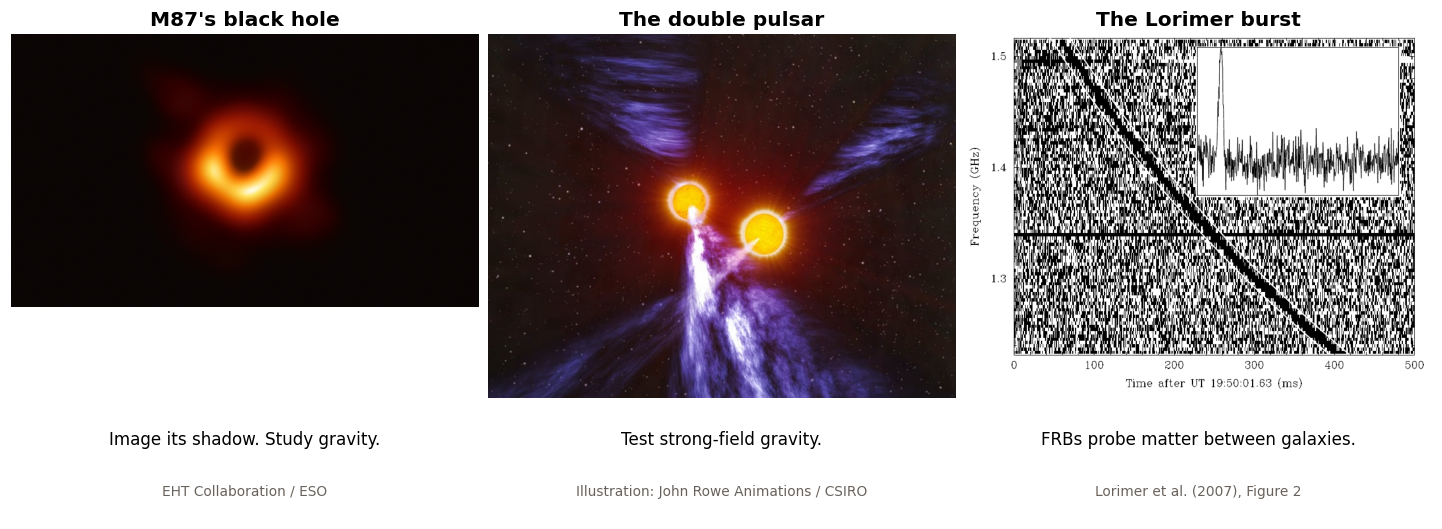

In [4]:
plot_radio_science()
plt.show()

### Faint signals over a wide range of wavelengths

A source with a flux density of 1 jansky is bright in many radio surveys:

$$1\ \mathrm{Jy}=10^{-26}\ \mathrm{W\,m^{-2}\,Hz^{-1}}.$$

This is received power per square metre, per hertz of bandwidth.
Many sources we study are thousands or millions of times fainter.
Radio astronomy spans roughly **0.3 mm to 30 m** in wavelength, five orders of
magnitude. [NRAO: introduction and units](https://www.cv.nrao.edu/~sransom/web/Ch1.html).

### What does a radio telescope measure?

A dish collects radio waves. The electric field drives a voltage in its receiver.
An interferometer measures correlations between antennas to resolve finer detail
on the sky. Unwanted signals from transmitters and electrical equipment are
**radio-frequency interference**, or RFI.

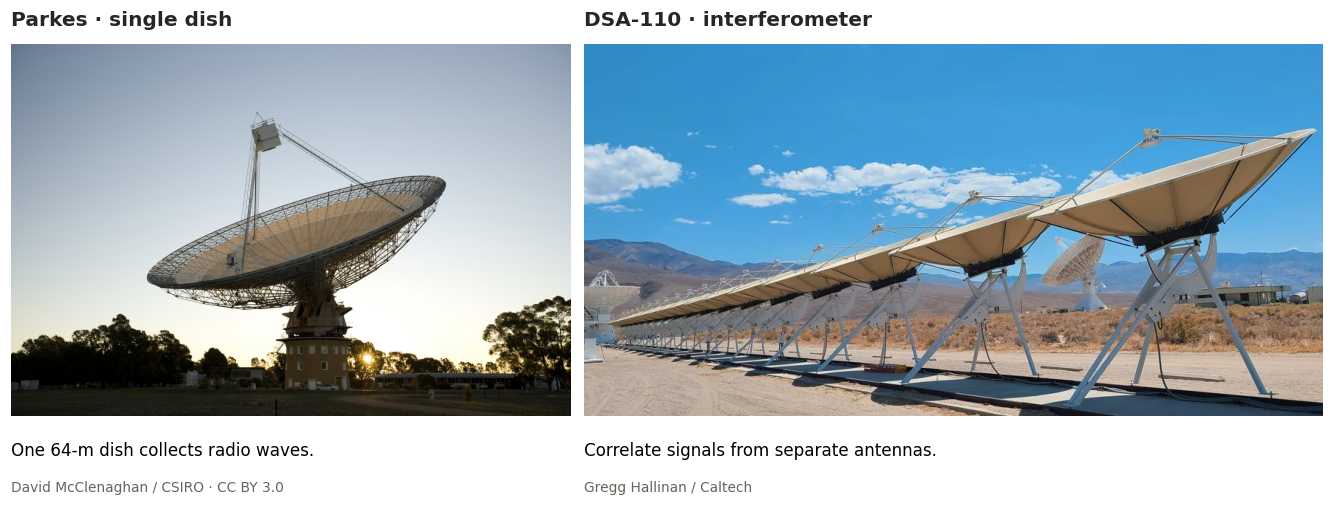

In [5]:
plot_telescopes()
plt.show()

Photos: [Parkes, David McClenaghan / CSIRO](https://commons.wikimedia.org/wiki/File:CSIRO_ScienceImage_7250_The_Radio_Telescope_at_Parkes.jpg)
([CC BY 3.0](https://creativecommons.org/licenses/by/3.0/));
[DSA-110, Gregg Hallinan / Caltech](https://webdev6.ipac.caltech.edu/page/dsa-110).

### I, Q and power

The incoming electric field drives a voltage in the antenna. The receiver
digitizes that voltage and separates it into frequency channels. In each channel,
**I** (in-phase) and **Q** (quadrature) give the amounts of two reference
oscillations, a quarter-cycle apart. Together they retain amplitude and phase.

$$v=I+iQ,\qquad A=\sqrt{I^2+Q^2},\qquad \phi=\mathrm{atan2}(Q,I).$$

The stored values are receiver counts. Antenna response and receiver gain connect
them to the electric field. Power is

$$P=|v|^2=I^2+Q^2.$$

For example, I = 3 and Q = 4 give amplitude 5 and power 25.
Here, I means a voltage component, not astronomical Stokes I.

Ideal receiver noise has Gaussian I and Q. Its power fluctuates strongly.
Our example rounds each component to a 4-bit integer from −8 to 7.
Two components fit in one byte: **4+4-bit** storage. The project uses power arrays.
After rounding, I and Q have discrete levels. More samples fill the histogram
bars; they cannot fill the gaps between integer values.

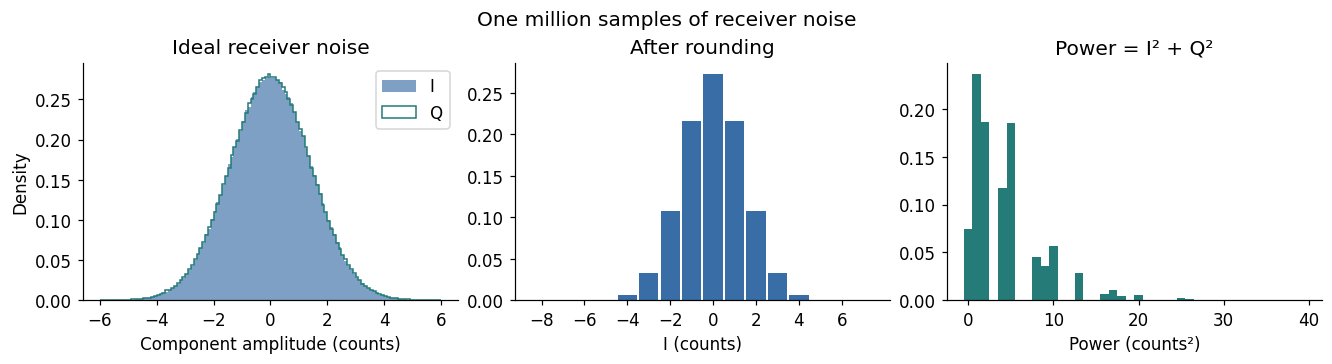

One sample: (-1+3j), power: 10 counts²


In [6]:
ideal = noise((1_000_000,), np.random.default_rng(12))
voltage = quantize(ideal)
power_example = voltage.real**2 + voltage.imag**2
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2), layout="constrained")
bins = np.linspace(-6, 6, 121)
axes[0].hist(ideal.real, bins=bins, density=True, alpha=0.65, color="#386da5", label="I")
axes[0].hist(ideal.imag, bins=bins, density=True, histtype="step", lw=1.8, color="#247b78", label="Q")
axes[0].set(title="Ideal receiver noise", xlabel="Component amplitude (counts)", ylabel="Density")
axes[0].legend()
axes[1].hist(voltage.real, bins=np.arange(-8.5, 8.5), density=True, rwidth=0.9, color="#386da5")
axes[1].set(title="After rounding", xlabel="I (counts)")
axes[1].set_xticks(np.arange(-8, 8, 2))
axes[2].hist(power_example, bins=np.arange(-0.5, 40.5), density=True, color="#247b78")
axes[2].set(title="Power = I² + Q²", xlabel="Power (counts²)")
fig.suptitle("One million samples of receiver noise")
plt.show()
print(f"One sample: {voltage[0]}, power: {power_example[0]:g} counts²")

**Polarization** describes the electric field's orientation. It can oscillate
along a line or rotate with right- or left-handed circular polarization.
It helps astronomers study magnetic fields and emission processes.
We use one linear feed, X. [NRAO: polarization](https://www.cv.nrao.edu/~sransom/web/Ch2.html#S3).

### From voltages to an image

| Product | Calculation | Meaning |
| --- | --- | --- |
| Complex voltage | `v = I + iQ` | Signal in one antenna and frequency channel |
| Power | `P = v v* = I² + Q²` | Signal strength, without voltage phase |
| Visibility | $V_{ab}=N^{-1}\sum_n v_a[n]v_b^*[n]$ | Correlation of antennas a and b, averaged over N samples |
| Dirty image | `D = F⁻¹[W V]` | Weighted Fourier imaging; blurred by incomplete sampling |

For antennas a and b, in frequency channel j:

$$\widehat V_{ab}(t_k,\nu_j)=\frac{1}{N}\sum_{n=0}^{N-1}v_a(t_k+n\Delta t,\nu_j)\,v_b^*(t_k+n\Delta t,\nu_j).$$

The averaging interval is $N\Delta t$. The star on `v*` means complex conjugate. In NumPy, one visibility is
`np.mean(v_a * v_b.conj())`. Different antennas give a cross-correlation;
the same antenna gives average power. The image formula assumes a small field
and calibrated data. Imaging needs phase; power alone is not enough.

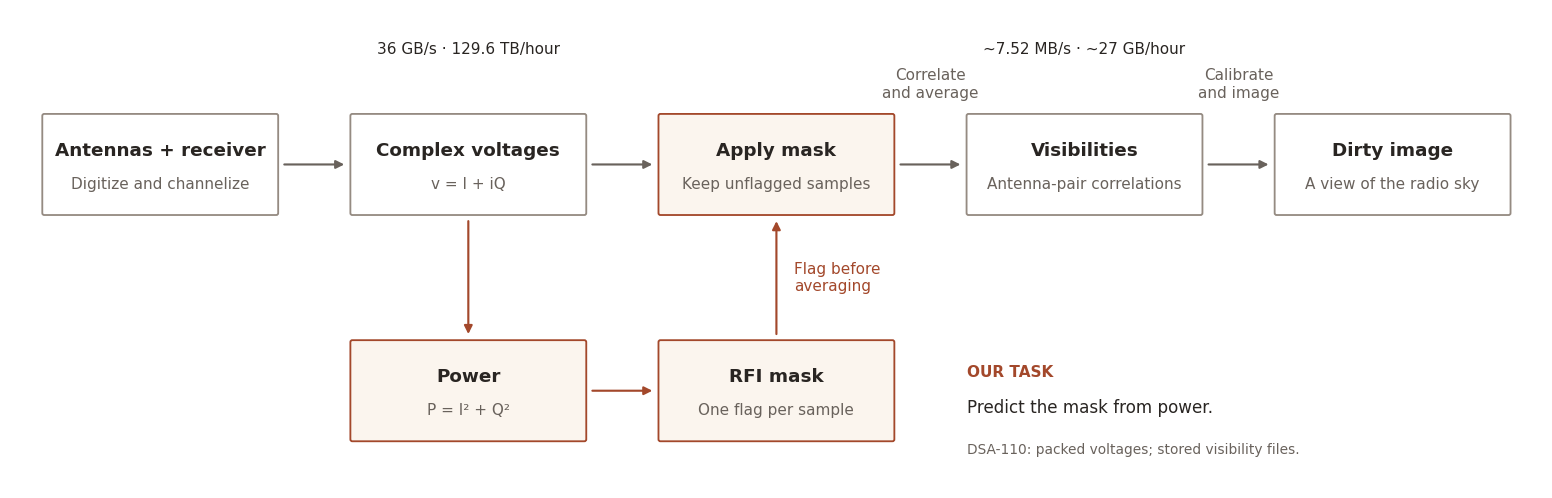

In [7]:
plot_signal_chain()
plt.show()

Read more: [NRAO's interferometry introduction, section 3.7](https://www.cv.nrao.edu/~sransom/web/Ch3.html#S7).

### Where can we remove RFI?

- **Before correlation:** flag voltages or their power. Short flags can retain
  clean samples around an impulse. This is our project.
- **After correlation:** flag visibilities. Many established imaging methods,
  including [AOFlagger](https://arxiv.org/abs/1002.1957), work here.
- **Image domain:** identify contamination in dirty images or fit a source model.

Averaging does not necessarily remove an impulse. Its contribution can contaminate
the whole visibility interval. The original clean and affected times can no longer
be separated. Choose N to suit the science before averaging the correlation products.

**DSA-110 example.** These figures describe the checked 96-input setup and
its saved products. MB and GB are decimal.

| Product | Resolution | Rate | One hour | Stored? |
| --- | --- | --- | --- | --- |
| Packed voltages, 96 antennas, 2 feeds | 32.768 µs; 6,144 × 30.52 kHz channels | **36 GB/s** across the array | **129.6 TB** | Candidate-triggered dumps, typically 2.0–3.1 s; about 72–111 GB |
| Visibilities, XX and YY | **12.885 s**; 768 × 244.14 kHz channels | **4.44 MB/s** complex-value payload; about **7.52 MB/s** in sampled files | **16 GB** payload; about **27 GB** in files | Written to disk for calibration and imaging |

The voltage hour is a continuous-storage estimate; only short dumps are saved.
These visibilities average eight frequency channels and 393,216 time samples.
XX and YY refer to correlations from the telescope's two linear feeds.
A trigger is a candidate, not necessarily a confirmed astronomical event.

For an overview of mitigation methods, read Table 1 in
[Buch et al., with Gregory Hellbourg: Real-time RFI Mitigation Techniques in
Radio Astronomy and their Practical Limitations](https://arxiv.org/html/2512.01954v2#S3).

## 2. What does RFI look like?

These are typical forms of interference seen across different radio telescope instruments.
A satellite can produce a carrier or digital band. Radar uses pulses.
Wireless links transmit in bursts. Electrical discharges produce impulses.
The examples include channel leakage, but are not complete communication protocols.
Receiver noise is omitted here so you can see the injected signals.

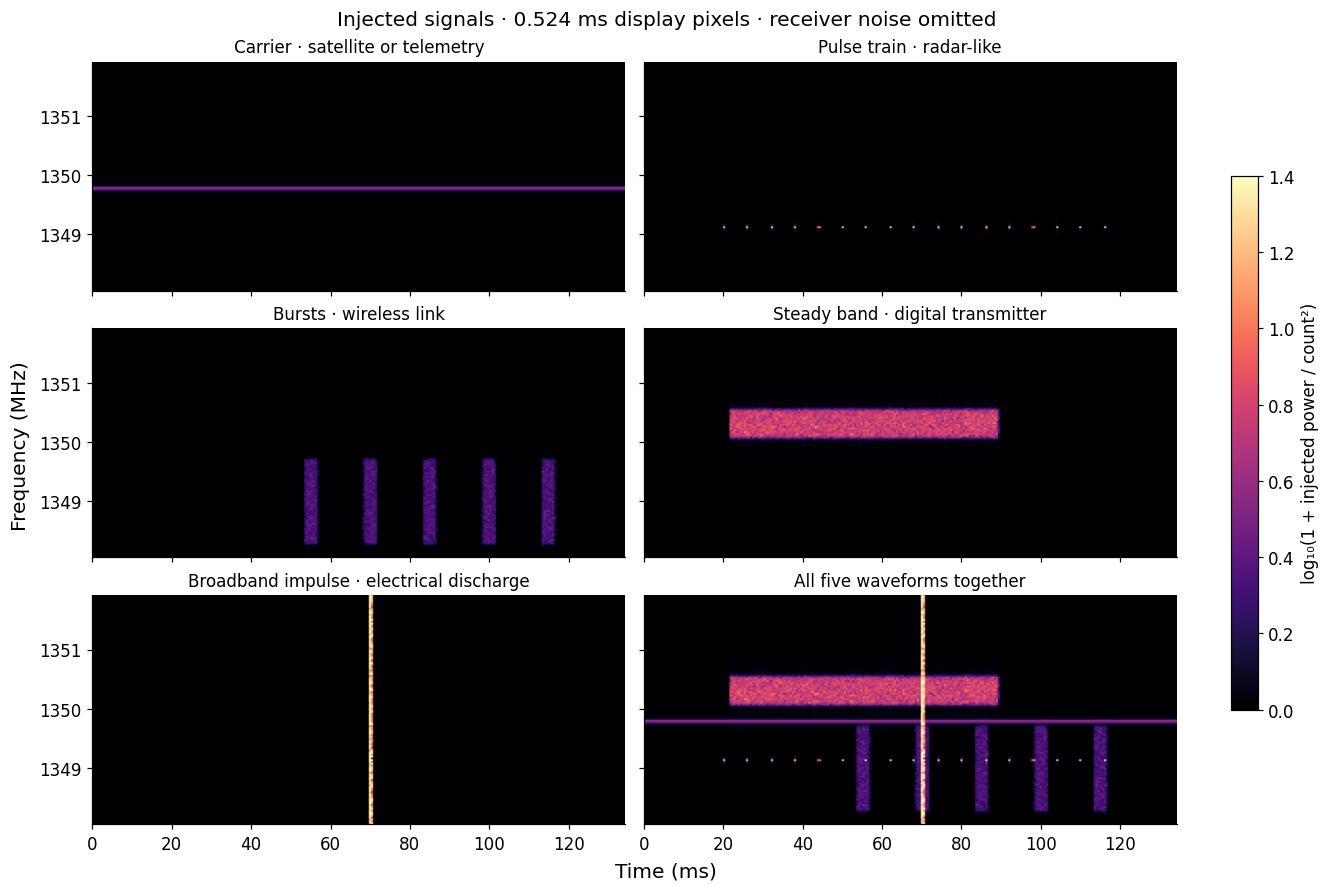

In [ ]:
plot_rfi_gallery()
plt.show()

A full satellite pass takes minutes. This example uses a straight overhead track
at 650 km altitude and 7.5 km/s. It shows Doppler shift and distance loss for
an isotropic receiver, without a dish beam. The carrier moves about two channels
over ten minutes. Within 134 ms it is almost stationary.
This display is separate from the training samples.

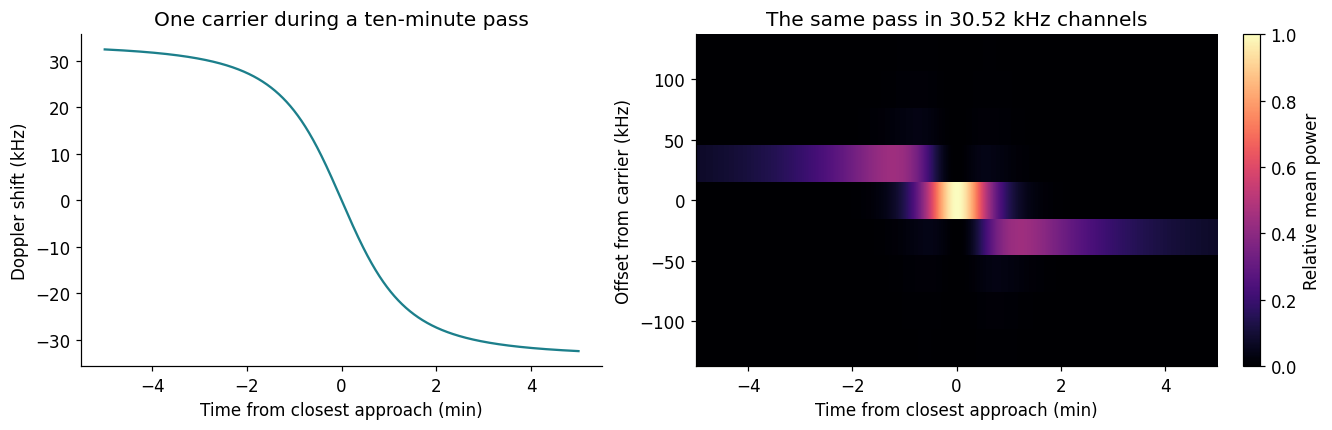

In [ ]:
plot_satellite_pass()
plt.show()

**Duty cycle** is the fraction of each cycle when a transmitter is on.
**Modulation** changes its phase, amplitude or frequency to carry information.

| Name | What the transmitter changes |
| --- | --- |
| Binary phase-shift keying (BPSK) | Switches between two phases |
| Quadrature phase-shift keying (QPSK) | Switches between four phases |
| Amplitude-shift keying (ASK) | Changes amplitude |
| Frequency-shift keying (FSK) | Switches between frequencies |

[Smith, Lynch and Pisano (2022)](https://arxiv.org/abs/2207.07642) show that
spectral kurtosis (SK) can miss signals whose power statistics resemble noise. Effective duty cycle
in a channel matters: a transmitter can be on for more than 50% of the time
and still produce a difficult case. Symbol rate and channel filtering affect this.
Our examples include 10%, 50%, 75%, 85% and 100%, with slow and fast modulation.

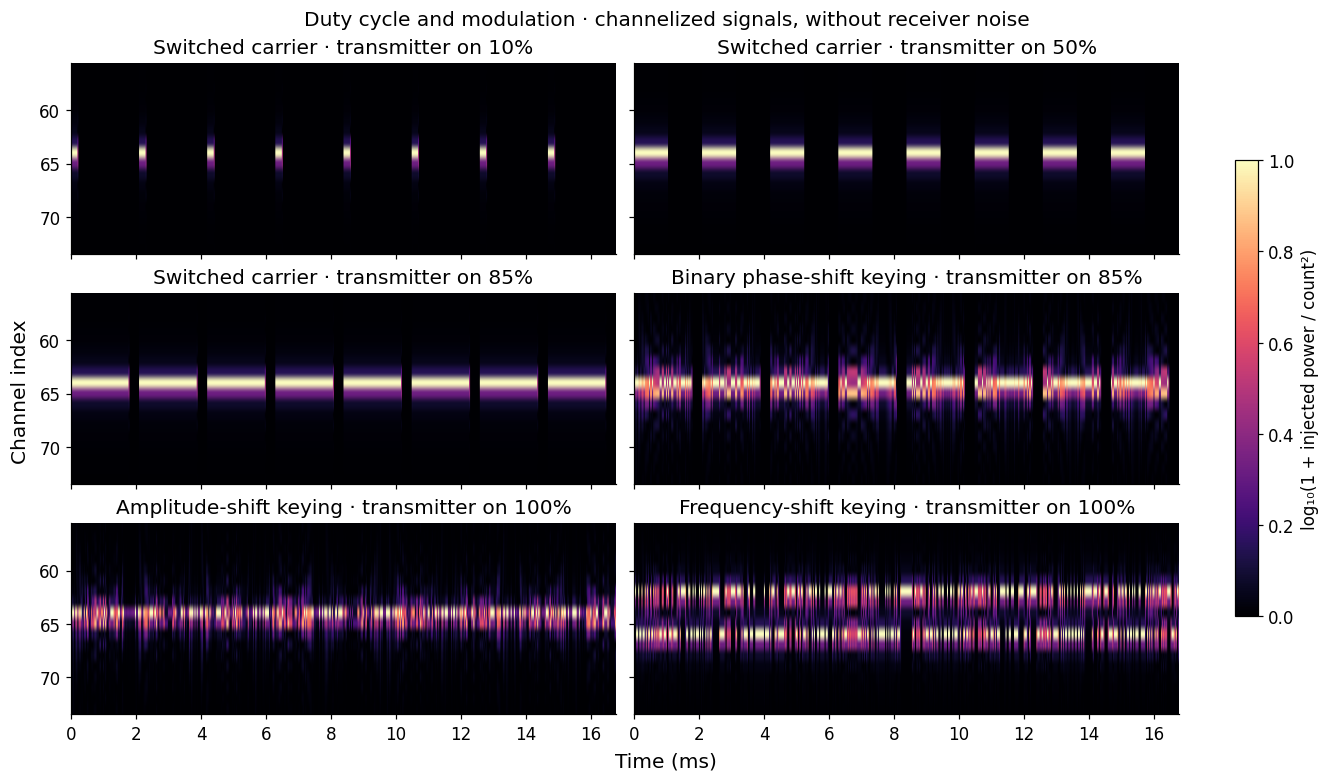

In [ ]:
plot_duty_gallery()
plt.show()

## 3. Read one training sample and its label

`dataset.csv` lists every supplied recording. Start with its first five rows.

In [8]:
catalog = pd.read_csv(DATA/"dataset.csv")
display(catalog.head())
display(catalog.groupby("split").size().rename("recordings").to_frame())

,sample_id,split,example,path,rfi_type,duration_s,time_step_us,channels,antennas,reference_power_ratio,peak_power_ratio,mean_power_ratio,label_noise_fraction,labelled_fraction,duty_cycle,symbol_rate,clipped_fraction,parameters
0,1,train,carrier,recordings/0001,carrier,0.134218,32.768,128,10,1.0,1.639620,0.010509,0.01,0.038281,NaN,NaN,3.814697e-07,recordings/0001/recording.json
1,2,train,radar,recordings/0002,radar,0.134218,32.768,128,10,20.0,29.076784,0.000345,0.01,0.000384,0.002991,NaN,5.340576e-06,recordings/0002/recording.json
2,3,train,wireless,recordings/0003,wireless,0.134218,32.768,128,10,1.0,12.079669,0.011071,0.01,0.013225,0.200587,NaN,3.051758e-06,recordings/0003/recording.json
3,4,train,digital,recordings/0004,digital,0.134218,32.768,128,10,1.0,26.653278,0.093079,0.01,0.112961,NaN,NaN,6.504059e-05,recordings/0004/recording.json
4,5,train,impulse,recordings/0005,impulse,0.134218,32.768,128,10,10.0,98.153954,0.021252,0.01,0.002438,NaN,NaN,3.416061e-04,recordings/0005/recording.json


,recordings
split,
test,40
train,100
validation,60


| Columns | Meaning |
| --- | --- |
| `sample_id`, `example`, `rfi_type` | Identifier, example name and signal family |
| `split` | `train` for fitting; `validation` for choosing settings; `test` for final evaluation |
| `path`, `parameters` | Data folder and short JSON file with sampling and simulator settings |
| `duration_s`, `time_step_us`, `channels`, `antennas` | Dimensions and sampling |
| `reference_power_ratio` | Source power / noise power before leakage and antenna gains; 0.1 means 10% |
| `peak_power_ratio`, `mean_power_ratio` | Received injected power / noise power: maximum and mean over the recording |
| `duty_cycle`, `symbol_rate` | On-time fraction within a cycle and symbols per second; blank when not applicable |
| `label_noise_fraction`, `labelled_fraction` | Label cutoff relative to noise power; fraction of samples labelled RFI |
| `clipped_fraction` | Fraction of samples with a component beyond the quantizer range |

All three splits are included. Keep all antennas and windows from one recording
in the same split. Choose settings on validation data, then evaluate once on test.
Neighboring samples are not independent experiments.
Strength and labels are for evaluation, not model inputs.

Input power: (4096, 128) float32
Target mask: (4096, 128) bool
Split: train Antenna: A00


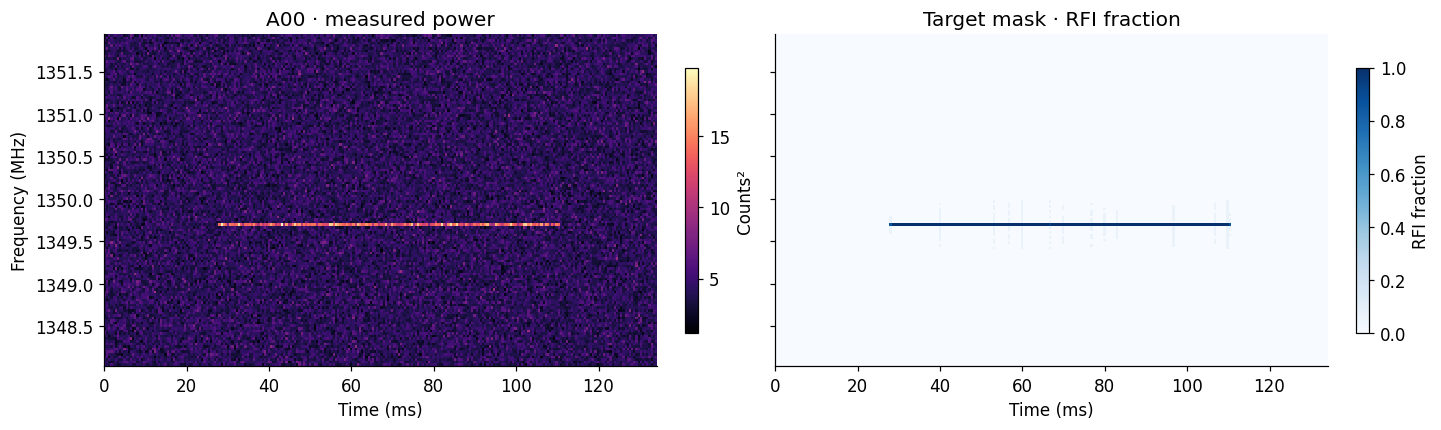

In [9]:
sample = load_sample(DATA, sample_id=18, antenna=0)
power = sample["power"]
labels = sample["rfi_mask"]
print("Input power:", power.shape, power.dtype)
print("Target mask:", labels.shape, labels.dtype)
print("Split:", sample["split"], "Antenna:", sample["antenna_names"][0])
plot_sample(sample, factor=16)
plt.show()

**This is the supervised segmentation pair.** Left: input power. Right: target
mask with the same time–frequency coordinates. A **flag** is a detector's
prediction that a sample should be removed. Neither mask changes the stored power.

The target is `True` where injected power is **at least 1% of the mean receiver-noise
power**. It is `False` below that cutoff, including faint leakage. Every sample is
scored. A flag below the cutoff counts as a false positive. The cutoff defines
the task; it does not guarantee that RFI is visible in one noisy sample.

This narrow-band transmitter uses binary phase-shift keying. Both panels show
the full 134 ms recording, averaged over 16 samples for display. The label panel
shows the fraction of positive labels in each display pixel. The stored target
is binary at native resolution.

| Axis | One training sample | Full recording |
| --- | --- | --- |
| Time | 4,096 values, 32.768 µs apart; 134.218 ms | Same |
| Frequency | 128 channels, 30.52 kHz apart; 3.91 MHz near 1350 MHz | Same |
| Antenna | One selected antenna | 10, A00–A09 |
| Feed | Linear X, removed from the sample axes | One |

This critically sampled channelizer has `Δt = N_channels / bandwidth`:
`128 / 3,906,250 Hz = 32.768 µs`. Display averaging is a separate choice.

The ZIP has **200 recordings**: 100 train, 60 validation and 40 test.
Each has ten antennas: **1,000 training pairs, 600 validation pairs and 400 test pairs**.
The ten antennas share transmitters; they are not ten independent recordings.
There are 180 RFI recordings, ten noise-only controls and ten astronomical-pulse controls.
Arrays use NumPy `.npy` files for partial reads. Power is stored as uint8 without
loss from the quantized values. The loader returns float32.

### Read all antennas from the same time interval

RFI can reach a few antennas or the whole array. Its received strength can differ.
All panels share time, frequency and colour scale. They are simultaneous
measurements, not ten unrelated injections.

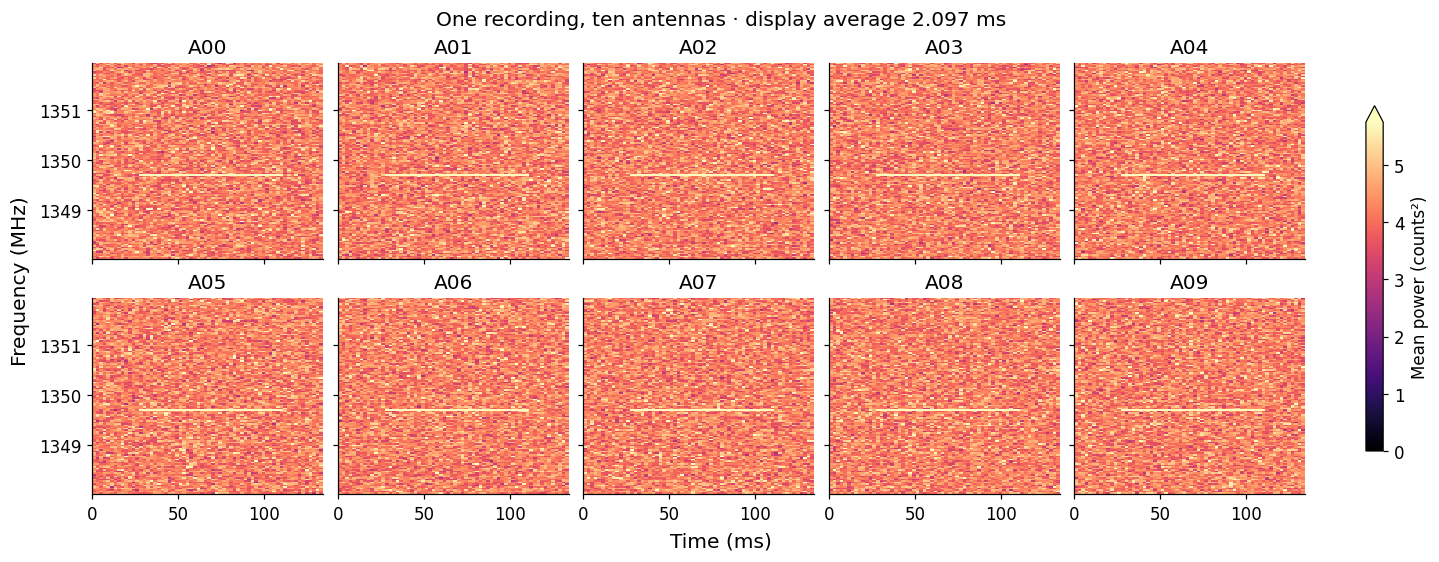

In [10]:
row = catalog.set_index("sample_id").loc[18]
recording = load_recording(DATA/row["path"])
plot_antenna_grid(recording, factor=64)
plt.show()

This grid averages 64 samples for display: **2.097 ms per pixel**.
Data and labels stay at native resolution. Use `factor=1` to see native samples.
`load_sample(DATA, sample_id=18, antenna=7)` selects A07 from this recording.
Here, all antennas receive the transmitter at the same time, with different strengths.

## 4. Run the baseline

This baseline is similar to the flagger currently used at DSA-110.
It uses the production spectral-kurtosis and bandpass detector code.

- `sk`: tests power fluctuations within each channel.
- `bandpass`: tests a channel's average power against other channels.
- `sk-bandpass`: combines both masks and expands clusters along frequency.

A detection marks the whole 134 ms antenna–channel block. Its mask can cover
more time than a pulse. Every removed native sample counts in the score.
Each antenna is tested separately. A flag on A00 does not flag A01–A09.

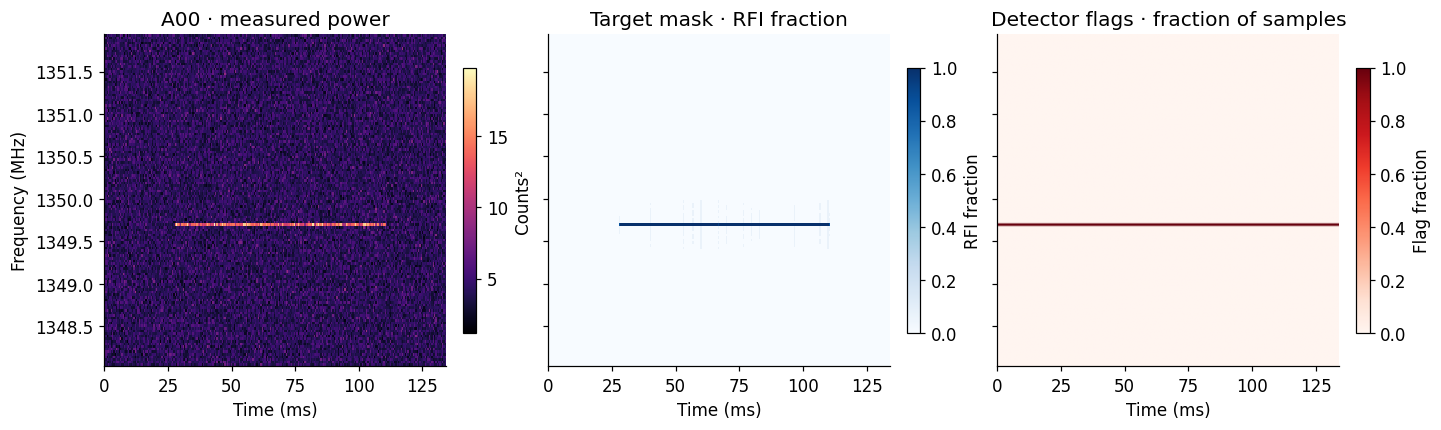

A00: 1 of 128 channels flagged for this block.


In [11]:
sk_mask = flag_rfi(power, method="sk")
bandpass_mask = flag_rfi(power, method="bandpass")
baseline_mask = flag_rfi(power, method="sk-bandpass")
plot_sample(sample, baseline_mask, factor=16)
plt.show()
print(f"A00: {baseline_mask[0].sum()} of {power.shape[1]} channels flagged for this block.")

### Spectral kurtosis

For M power values in one channel:

$$S_1=\sum_{n=1}^{M}P_n,\quad S_2=\sum_{n=1}^{M}P_n^2,\quad \widehat{\mathrm{SK}}=\frac{M+1}{M-1}\left(\frac{M S_2}{S_1^2}-1\right).$$

SK is near 1 for ideal Gaussian voltage noise. A value outside its lower and
upper thresholds triggers a flag. It uses power fluctuations, not just average
power. Quantization and finite samples affect its distribution.
The reference uses M = 64, 256, 1024 and 4096 and combines their detections.
[Nita and Gary: the estimator](https://arxiv.org/abs/1005.4371).

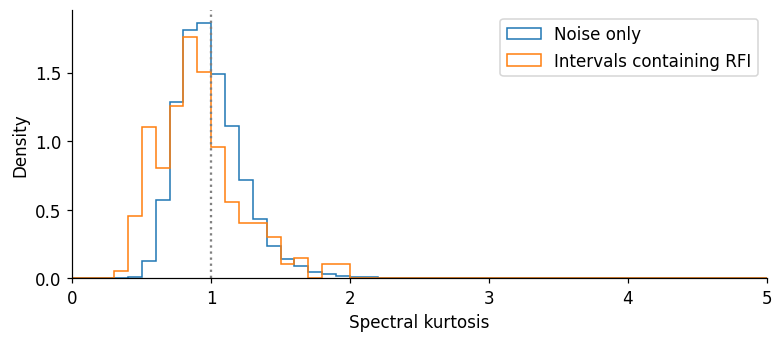

M = 64   interval = 2.097 ms


In [12]:
m = 64
s1, s2 = power_sums(power, m)
sk = spectral_kurtosis(s1, s2, m)
clean_id = int(catalog.query("split == 'validation' and rfi_type == 'clean'").iloc[0].sample_id)
clean = load_sample(DATA, sample_id=clean_id, antenna=0)
clean_s1, clean_s2 = power_sums(clean["power"], m)
clean_sk = spectral_kurtosis(clean_s1, clean_s2, m)
fig, ax = plt.subplots(figsize=(7, 3), layout="constrained")
bins = np.linspace(0, 5, 51)
contains_rfi = average_power(labels, m) > 0
ax.hist(clean_sk.ravel(), bins=bins, density=True, histtype="step", label="Noise only")
ax.hist(sk[contains_rfi], bins=bins, density=True, histtype="step", label="Intervals containing RFI")
ax.axvline(1, color="grey", ls=":")
ax.set(xlabel="Spectral kurtosis", ylabel="Density", xlim=(0, 5))
ax.legend()
plt.show()
print("M =", m, "  interval =", round(m*32.768/1000, 3), "ms")

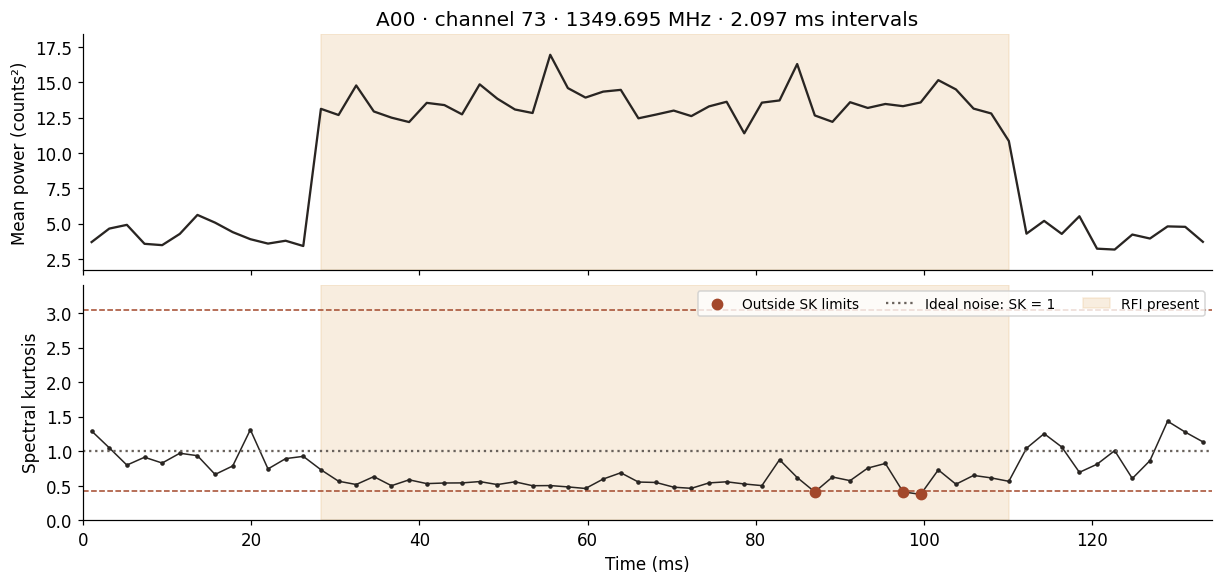

In [13]:
plot_kurtosis(sample, m=64)
plt.show()

The orange histogram selects intervals that contain labelled RFI.
The time plot follows the brightest channel in A00. Shading marks intervals
with labelled RFI. Dashed lines are the SK detector limits for M = 64; red dots
cross a limit. Here, RFI makes SK fall below the lower limit.
We use labels only to explain the result, not as input to the detector.

### Bandpass outlier

Average each channel over a 4,096-sample block: `B_c = mean(P_c)`.
Across channels, calculate `b = median(B)` and
`s = 1.4826 × median(|B − b|)`. Flag channel c when `|B_c − b| > k s`.
The reference code sets k for this channel count. Keep its default for this exercise.
A steady carrier can change B while leaving some fluctuation tests ineffective.
A broad band can raise the reference itself and become harder to detect.

## 5. Score the masks

A true positive (TP) is correctly flagged RFI. A false positive (FP) is a
flag where the target mask is zero. A false negative (FN) is missed labelled RFI.
A true negative (TN) has a zero target and stays unflagged.

**Precision = TP / (TP + FP):** what fraction of flags are correct?
**Recall = TP / (TP + FN):** what fraction of labelled RFI was found?
**False-positive rate = FP / (FP + TN):** what fraction of negative samples was flagged?
Also report the total fraction removed.
Precision is undefined when there are no flags. Recall is zero when a detector
misses all positive labels, and undefined when there are no positive labels.

,precision,recall,false_positive_rate,removed
sk,61.6%,93.9%,0.3%,0.8%
bandpass,61.6%,93.9%,0.3%,0.8%
sk-bandpass,61.6%,93.9%,0.3%,0.8%


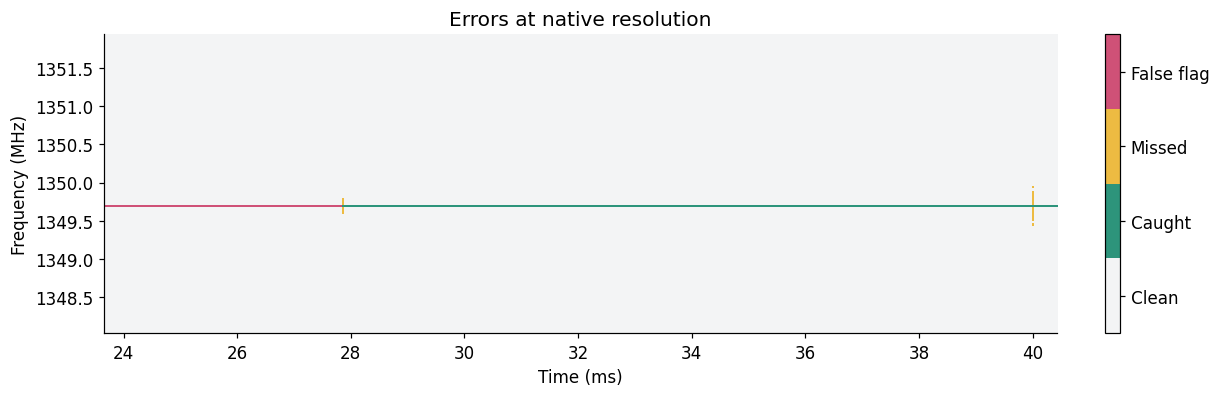

In [14]:
masks = {"sk": sk_mask, "bandpass": bandpass_mask, "sk-bandpass": baseline_mask}
scores = pd.DataFrame({name: score_mask(mask, labels) for name, mask in masks.items()}).T
display(scores[["precision", "recall", "false_positive_rate", "removed"]].style.format("{:.1%}", na_rep="—"))
first = max(0, int(np.flatnonzero(labels.any(axis=1))[0])-128) if labels.any() else 0
first = min(first, len(power)-512)
plot_errors(sample, baseline_mask, first=first)
plt.show()

Here the three methods flag the same main channel. Precision is below 100%
because they also remove times before and after the transmission. Some labelled
power outside that channel is missed. This selected teaching example is not a
summary of performance across the dataset. Try recording 4 to see different masks.

Keep the reference settings fixed for the first comparison.
To study accumulation length later, use `m_values=(64,)` or `(256,)`.
Bandpass still averages the full block. M = 1 works for displaying native power,
but not for SK. Baseline windows must start at multiples of 4,096.

A simple native-power threshold helps distinguish the benefit of short flags
from the benefit of a neural network.

In [15]:
short_sk = flag_rfi(power, method="sk", m_values=(64,))
threshold = float(np.quantile(clean["power"], 0.999))
native_mask = flag_power(power, threshold)
print("Native power threshold:", threshold, "counts²")
display(pd.DataFrame({"SK, M=64": score_mask(short_sk, labels),
                      "native power": score_mask(native_mask, labels)}).T[
                          ["precision", "recall", "false_positive_rate", "removed"]])

Native power threshold: 29.0 counts²


,precision,recall,false_positive_rate,removed
"SK, M=64",0.615967,0.938616,0.003016,0.007812
native power,0.307102,0.059524,0.000692,0.000994


## 6. Make a controlled example

Keep the seed fixed while changing one parameter. This keeps receiver noise fixed.
`strength=10` sets reference on-state power to ten times the noise power. Leakage,
pulse width and antenna gains affect received power in a channel.
For a pulsed carrier, `duty_cycle=0.85` keeps the transmitter on for 85% of each cycle.
The returned arrays are channelized power and binary truth.

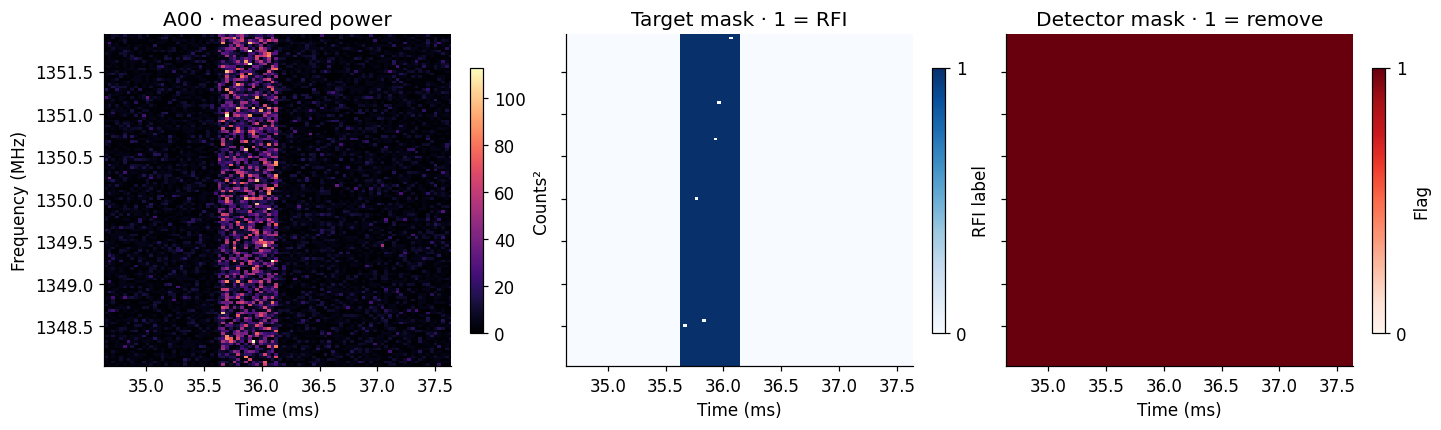

In [16]:
generated = simulate_recording(seed=52, rfi="impulse", strength=10)
prediction = flag_rfi(generated["power"], method="sk-bandpass")
burst_ms = generated["metadata"]["events"][0]["start_s"]*1000
plot_sample(generated, prediction, antenna=0, factor=1,
            time_ms=(burst_ms-1, burst_ms+2))
plt.show()

This broadband impulse is a harder case. It raises power in most channels
briefly. The bandpass test can miss a rise shared across the band. Spectral
kurtosis and channel expansion can flag the entire block. That catches the
impulse but discards much more data than its short duration requires.

**Save once, read later.** The default lasts 134 ms. Use `duration_s=4` for
about four seconds, rounded up to whole processing blocks. The reader handles
block boundaries. Longer recordings need more memory; start with the default.

In [17]:
output = Path("outputs/my_impulse_v1.0")
if not output.exists():
    save_recording(output, generated)
saved = load_recording(output, start=0, samples=4096)
np.testing.assert_array_equal(saved["power"], generated["power"])
np.testing.assert_array_equal(saved["rfi_mask"], generated["rfi_mask"])
print(output)

outputs/my_impulse_v1.0


### Keep astronomical bursts

This control contains a bright, dispersed astronomical pulse and receiver noise,
with **no RFI**. Lower frequencies arrive later. The existing RFI mask is zero
everywhere: this is a signal to keep. Both panels show antenna A00.
Power is averaged over 64 samples for display; stored data and scores use native samples.
Test whether a detector preserves the pulse. Fainter astronomical signals need separate checks.

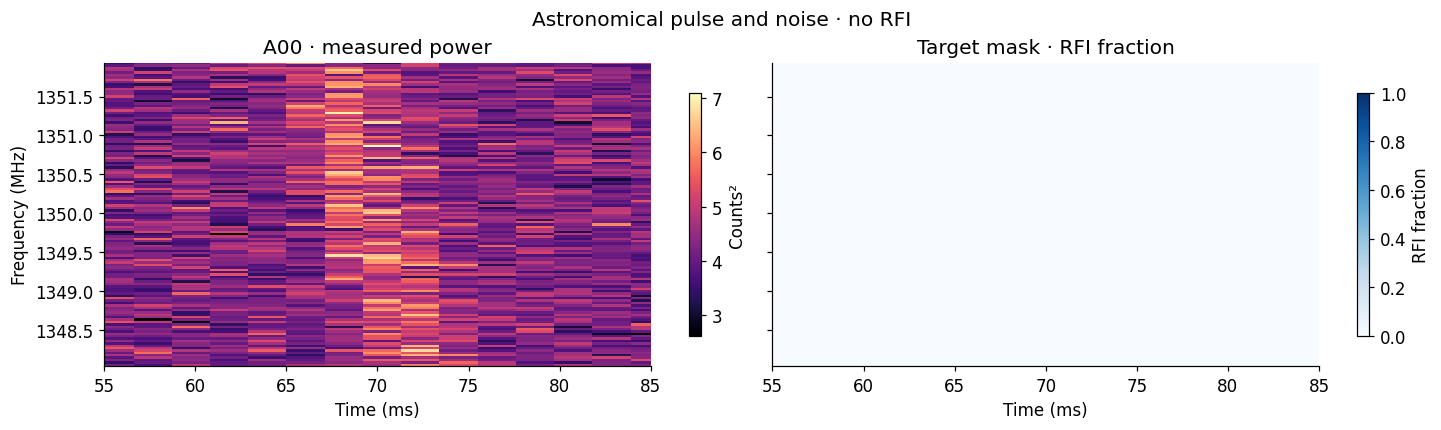

RFI labels: 0


In [18]:
sky_id = int(catalog.query("split == 'validation' and rfi_type == 'sky'").iloc[0].sample_id)
sky = load_sample(DATA, sample_id=sky_id, antenna=0)
fig = plot_sample(sky, factor=64, time_ms=(55, 85))
fig.suptitle("Astronomical pulse and noise · no RFI")
plt.show()
print("RFI labels:", sky["rfi_mask"].sum())

## 7. Tasks

### Bring to the next meeting

Work as one team. Each person should be able to load a sample and explain its mask.

1. Run `sk`, `bandpass` and `sk-bandpass`. Tabulate precision, recall,
   false-positive rate and removal fraction for each RFI family.
2. Plot one input with its label and each detector's mask. Explain one miss
   and one false flag. Change one parameter to test your explanation.
3. Compare 10%, 50%, 75%, 85% and 100% duty cycles. Plot recall against duty
   cycle for each detector. Keep strength, period and the noise seed fixed.
4. Each person reads one ML RFI paper. Bring one figure and fill one row below.

| Paper (author et al.) | Dataset: simulated or real | Telescope: dish or interferometer | Modality | Method / ML architecture | Metrics and test split |
| --- | --- | --- | --- | --- | --- |
| Your choice | | | | | |

Suggested papers, one per person:

1. [Akeret et al.: RFI mitigation using deep convolutional neural networks](https://arxiv.org/abs/1609.09077).
2. [Vafaei Sadr et al.: Deep learning improves identification of RFI](https://arxiv.org/abs/2005.08992).
3. [Yang et al.: Deep residual detection of RFI for FAST](https://arxiv.org/abs/2001.06669).
4. [Kerrigan et al.: Optimizing sparse RFI prediction using deep learning](https://arxiv.org/abs/1902.08244).

**You can choose any ML RFI mitigation paper you like.** These are suggestions.
Compare label definitions and test splits before comparing reported scores.
Smith et al. is extra reading for the baseline, not one of the ML choices.

### Train a small U-Net

Input: one antenna's native power, shape `(4096, 128)`.
Target: its binary RFI mask. Output: one RFI probability per time–frequency pixel.
A PyTorch batch has shape `(batch, 1, 4096, 128)` for both input and target.
The `1` is one power image, not ten antennas combined. Threshold the output
probabilities to produce a Boolean mask. Each antenna is a separate training pair.
Share weights across antennas. Do not feed SK, labels, sample IDs or
transmitter parameters into the network.

Start with the supplied training split. For this ideal dataset, pool the power
values from **all noise-only training recordings** (`split == 'train'` and
`rfi_type == 'clean'`) across time, frequency and antennas. Calculate **one mean
and one standard deviation** from those pooled values. Use `(power - mean) / std`
for every U-Net input in train, validation and test. Do not calculate a separate
normalization for each recording. Leave labels unchanged and give the classical
detectors the original, unnormalized power.

Choose the output threshold and other settings on validation data. Keep them fixed
before scoring the test split. Compare at a matched clean-validation false-positive
rate, and also retain the baseline reference setting. A GPU runtime is useful for training.

For more training data, use new seeds and vary strength, location, duration,
duty and modulation. Keep the supplied validation and test recordings unchanged.

Include these plots in the report:

- Input, truth and predicted mask for one success and one failure.
- Precision–recall curves and average precision for the U-Net. Add baseline
  points for the three fixed baseline masks. One hard mask does not define
  a precision–recall curve.
- Recall versus source power as a percentage of noise power, for each family.
  Record both reference strength and received peak power.
- Recall versus duty cycle, separately for each modulation.
- Clean data removed and astronomical signal retained. Select the `clean` and
  `sky` controls from the CSV. The astronomical pulse has no RFI labels.
  Do not treat it as an unwanted burst. A bright pulse can appear in single-antenna power.



Further reading: [Buch et al. on RFI mitigation methods (Table 1)](https://arxiv.org/html/2512.01954v2#S3),
[Price on channelizers](https://arxiv.org/abs/1607.03579),
[Smith et al. on SK failure cases](https://arxiv.org/abs/2207.07642), and
[NRAO on short-pulse blanking](https://science.nrao.edu/facilities/vla/docs/manuals/opt-manual/resource-catalog-tool/rfi-blanking).
Experiments work offline after installation. Reading links need internet.

## Part 7 walkthrough: your first baseline experiments
Run this notebook from top to bottom with **Python (CS163 RFI)**. It covers the four “Bring to the next meeting” tasks. Start here before training a U-Net.

We use **validation data** for the baseline comparison and FAR sweep; keep test data untouched until the final comparison. All ten antennas of a recording stay together. Figures and CSV files go to `outputs/part7/validation/`.

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import display
from cs163_rfi import load_sample, load_recording, flag_rfi, score_mask, simulate_recording
from cs163_rfi.plotting import plot_sample, plot_errors

torch.set_num_threads(1)
ROOT = Path.cwd()
if not (ROOT / "pyproject.toml").exists():
    ROOT = ROOT.parent
assert (ROOT / "pyproject.toml").exists(), "Start Jupyter in the project or notebooks directory"
DATA = ROOT / "data/starter-v1.0"
BASELINE_SPLIT = "validation"
BASELINE_FAR = 1e-4
OUT = ROOT / "outputs/part7" / BASELINE_SPLIT
OUT.mkdir(parents=True, exist_ok=True)
METHODS = ("sk", "bandpass", "sk-bandpass")
catalog = pd.read_csv(DATA / "dataset.csv")
display(catalog.groupby(["split", "rfi_type"]).size().unstack(fill_value=0))

## Task 1: evaluate every validation recording
Each detector gets original power, without normalization. A full recording contains all ten antennas. We first save TP, FP, FN, and TN per recording, then **sum counts before calculating ratios**. This weights every native pixel equally. Averaging per-recording precision would answer a different question.

`clean` and `sky` are controls: they have no positive RFI labels, so recall is undefined. Their false-positive rate measures how much data is incorrectly removed.

**How the 60 recordings become one point:** for each method and FAR, add TP, FP, FN, and TN over every native pixel, all ten antennas, and all validation recordings. Then calculate `precision = sum(TP)/(sum(TP)+sum(FP))`, `recall = sum(TP)/(sum(TP)+sum(FN))`, and `FPR = sum(FP)/(sum(FP)+sum(TN))`. This is pixel micro-averaging, not the mean of 60 recalls. Recordings with more positive pixels contribute more to pooled recall. Clean/sky controls add false positives and true negatives but no positive labels. The per-recording and per-antenna CSVs let you trace each contribution.


In [ ]:
def pooled_pixel_metrics(frame, groups):
    """Sum native-pixel counts first; never average individual precision/recall."""
    totals = frame.groupby(groups)[["tp", "fp", "fn", "tn"]].sum()
    total_tp, total_fp = totals["tp"], totals["fp"]
    total_fn, total_tn = totals["fn"], totals["tn"]
    totals["target_pixels"] = total_tp + total_fn
    totals["flagged_pixels"] = total_tp + total_fp
    totals["precision"] = total_tp / (total_tp + total_fp).replace(0, np.nan)
    totals["recall"] = total_tp / (total_tp + total_fn).replace(0, np.nan)
    totals["false_positive_rate"] = total_fp / (total_fp + total_tn).replace(0, np.nan)
    totals["removed"] = (total_tp + total_fp) / (total_tp + total_fp + total_fn + total_tn).replace(0, np.nan)
    return totals

rows = []
mask50_rows = []
baseline_frame = catalog.loc[catalog["split"].eq(BASELINE_SPLIT)]
assert len(baseline_frame) and baseline_frame.split.eq("validation").all()
for i, row in enumerate(baseline_frame.itertuples(), 1):
    recording = load_recording(DATA / row.path)
    for method in METHODS:
        flags = flag_rfi(recording["power"], method=method, far=BASELINE_FAR)
        rows.append(dict(sample_id=row.sample_id, split=row.split,
                         rfi_type=row.rfi_type, method=method,
                         **score_mask(flags, recording["rfi_mask"])))
        # One foreground mask instance per antenna; retain counts for AP@50.
        for antenna in range(flags.shape[1]):
            antenna_score = score_mask(flags[:, antenna, :, 0], recording["rfi_mask"][:, antenna, :, 0])
            mask50_rows.append(dict(sample_id=row.sample_id, antenna=antenna,
                                    rfi_type=row.rfi_type, method=method, **antenna_score))
    if i % 20 == 0:
        print(f"Finished {i}/{len(baseline_frame)} {BASELINE_SPLIT} recordings")
per_recording = pd.DataFrame(rows)
per_recording.to_csv(OUT / "baseline_per_recording.csv", index=False)
summary = pooled_pixel_metrics(per_recording, ["rfi_type", "method"])
counts = summary[["tp", "fp", "fn", "tn"]].copy()
summary.to_csv(OUT / "baseline_by_family.csv")
metrics = ["precision", "recall", "false_positive_rate", "removed"]
display(summary[metrics].style.format("{:.2%}", na_rep="undefined"))
mask50_detail = pd.DataFrame(mask50_rows)
mask50_detail.to_csv(OUT / "baseline_per_antenna.csv", index=False)

# Show totals for ALL validation recordings, separately from single-example counts.
pooled_reference = pooled_pixel_metrics(per_recording, "method")
pooled_reference.to_csv(OUT / "baseline_pooled_reference.csv")
print(f"TOTALS: {len(baseline_frame)} {BASELINE_SPLIT} recordings, all antennas; FAR={BASELINE_FAR:g}")
print("Precision = TOTAL TP / (TOTAL TP + TOTAL FP); recall = TOTAL TP / (TOTAL TP + TOTAL FN)")
display(pooled_reference.rename(columns={name: f"total_{name}" for name in ("tp", "fp", "fn", "tn")}))

# Running totals demonstrate how successes and failures accumulate across recordings.
cumulative_reference = per_recording.sort_values(["method", "sample_id"]).copy()
count_columns = ["tp", "fp", "fn", "tn"]
cumulative_reference[count_columns] = cumulative_reference.groupby("method")[count_columns].cumsum()
cumulative_reference["recordings_accumulated"] = cumulative_reference.groupby("method").cumcount() + 1
cumulative_reference["precision"] = cumulative_reference.tp / (cumulative_reference.tp + cumulative_reference.fp).replace(0, np.nan)
cumulative_reference["recall"] = cumulative_reference.tp / (cumulative_reference.tp + cumulative_reference.fn).replace(0, np.nan)
cumulative_reference.to_csv(OUT / "baseline_cumulative_reference.csv", index=False)
last_counts = cumulative_reference.groupby("method").tail(1).set_index("method")[count_columns]
pd.testing.assert_frame_equal(last_counts.sort_index(), pooled_reference[count_columns].sort_index())
assert per_recording.groupby("method").sample_id.nunique().eq(len(baseline_frame)).all()
assert pooled_reference.target_pixels.nunique() == 1, "All methods must see the same ground truth"


### Comparison 1: validation ROC and precision–recall curves
One ROC panel and one PR panel each contain three lines: SK, bandpass, and combined. Points sweep nominal FAR on the same validation recordings, pooling confusion counts over all antennas. Stars mark the reference FAR (`1e-4`). ROC uses measured false-positive rate on x and recall (true-positive rate) on y; PR uses recall on x and precision on y. Family details remain in CSV tables.

**Thresholds and outputs:** baselines output Boolean masks, not probabilities. FAR determines the internal SK lower/upper limits and bandpass outlier cutoff; combined takes their union and expands frequency clusters. The metric calculation applies no additional threshold. Truth uses the fixed 1% injected-power/noise cutoff. Nominal FAR differs from the final measured FPR because multiple tests and mask expansion are combined. Undefined ratios remain missing, not zero.

This comparison uses validation; reserve test for evaluation after settings are frozen. These are sampled FAR sweeps, not complete probability-ranked curves. No artificial endpoints or AUC values are added. Combined may improve recall at a precision cost; let the measurements establish the trade-off.

**mAP@50 uses mask IoU ≥ 0.50**, not a probability threshold of 0.50 or pixel average precision. This dataset has no object IDs, so we explicitly treat the entire binary RFI mask of each antenna/recording as one foreground instance, even when it contains disconnected regions. Each nonempty predicted mask is one detection. A nonempty truth is one target. Predictions on clean/sky controls are false positives; missed targets remain false negatives. This whole-mask convention differs from connected-component or bounding-box detection benchmarks.

The baselines supply Boolean masks without confidence scores. All detections therefore have equal confidence and enter as one tied group. AP@50 uses the 101-point interpolated precision envelope over recall 0…1, with zero precision beyond achieved recall. There is one foreground class (RFI), so **mAP@50 = AP@50**; signal families are diagnostic subsets, not additional classes. No-target subsets have undefined AP. Keep pixel PR and instance PR@50 separate.


In [ ]:
# Sweep FAR while retaining the original baseline measurements and settings.
FAR_VALUES = np.array([1e-6, 1e-5, 1e-4, 1e-3, 1e-2])
pr_rows = per_recording.assign(far=BASELINE_FAR).to_dict("records")
for far in FAR_VALUES:
    if far == BASELINE_FAR:
        continue
    for row in baseline_frame.itertuples():
        recording = load_recording(DATA / row.path)
        for method in METHODS:
            flags = flag_rfi(recording["power"], method=method, far=float(far))
            pr_rows.append(dict(sample_id=row.sample_id, split=row.split, rfi_type=row.rfi_type,
                                method=method, far=float(far),
                                **score_mask(flags, recording["rfi_mask"])))
    print(f"Finished baseline PR sweep: FAR={far:g}")
pr_detail = pd.DataFrame(pr_rows)
pr_detail.to_csv(OUT / "baseline_pr_sweep_per_recording.csv", index=False)

def pixel_pr_table(frame, groups):
    # The plotted points use TOTAL counts, not any one successful/failed example.
    return pooled_pixel_metrics(frame, groups).reset_index()

assert pr_detail.split.eq(BASELINE_SPLIT).all(), "Do not mix train, validation, or test"
assert not pr_detail.duplicated(["sample_id", "method", "far"]).any()
coverage = pr_detail.groupby(["method", "far"]).sample_id.nunique()
assert coverage.eq(len(baseline_frame)).all(), "Each curve point must include all validation recordings"
pixel_overall = pixel_pr_table(pr_detail, ["method", "far"])
pixel_family = pixel_pr_table(pr_detail, ["rfi_type", "method", "far"])
pixel_overall.to_csv(OUT / "baseline_pr_overall.csv", index=False)
pixel_family.to_csv(OUT / "baseline_pr_by_family.csv", index=False)
# Display the exact totals used by every plotted FAR point.
print(f"ROC/PR points: cumulative pixel totals across {len(baseline_frame)} validation recordings and all antennas")
display(pixel_overall.rename(columns={name: f"total_{name}" for name in ("tp", "fp", "fn", "tn")}))
reference_from_curve = pixel_overall.loc[pixel_overall.far.eq(BASELINE_FAR)].set_index("method")
check_columns = ["tp", "fp", "fn", "tn", "precision", "recall", "false_positive_rate"]
pd.testing.assert_frame_equal(reference_from_curve[check_columns].sort_index(),
                              pooled_reference[check_columns].sort_index())
colors = dict(zip(METHODS, ["#386da5", "#00867F", "#E36B4B"]))
method_labels = {"sk": "SK", "bandpass": "Bandpass", "sk-bandpass": "SK + bandpass"}

def plot_roc_pr(frame, parameter, parameter_label, title, filename, reference=None):
    """One row, two panels, three method lines; ordered by the swept parameter."""
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), layout="constrained")
    coordinates = [("false_positive_rate", "recall"), ("recall", "precision")]
    for method_index, method in enumerate(METHODS):
        curve = frame.loc[frame.method.eq(method)].sort_values(parameter)
        for ax, (x, y) in zip(axes, coordinates):
            # Undefined ratios stay NaN so lines break rather than inventing zeros.
            ax.plot(curve[x], curve[y], "o-", color=colors[method], lw=2,
                    label=method_labels[method])
            if reference is not None:
                ref = curve.loc[curve[parameter].eq(reference)]
                ax.scatter(ref[x], ref[y], marker="*", s=170, color=colors[method],
                           edgecolor="black", zorder=5)
            else:
                # Labels indicate strength/duty values, not detector thresholds.
                for _, point in curve.iterrows():
                    if pd.notna(point[x]) and pd.notna(point[y]):
                        ax.annotate(f"{point[parameter]:g}", (point[x], point[y]),
                                    xytext=(5, 6 + 10*method_index), textcoords="offset points",
                                    fontsize=8, color=colors[method])
    axes[0].set(title="ROC" if reference is not None else "ROC space · fixed detector thresholds",
                xlabel="False-positive rate = FP / (FP + TN)", ylabel="Recall = TP / (TP + FN)")
    axes[1].set(title="Precision–recall" if reference is not None else "PR space · fixed detector thresholds",
                xlabel="Recall = TP / (TP + FN)", ylabel="Precision = TP / (TP + FP)")
    for ax in axes:
        ax.set(xlim=(-0.02, 1.02), ylim=(-0.02, 1.02))
        ax.grid(alpha=0.2)
        ax.legend(loc="best")
    explanation = (f"Stars: {parameter_label} = {reference:g}" if reference is not None
                   else f"Point labels: {parameter_label}; FAR = {BASELINE_FAR:g}")
    fig.suptitle(title + "\n" + explanation, fontsize=12)
    fig.savefig(OUT / f"{filename}.png", dpi=180, bbox_inches="tight")
    fig.savefig(OUT / f"{filename}.pdf", bbox_inches="tight")
    plt.show()
    return fig

baseline_figure = plot_roc_pr(pixel_overall, "far", "nominal FAR",
                             f"1. Baseline comparison · pooled totals, {len(baseline_frame)} validation recordings, all antennas",
                             "baseline_roc_precision_recall", reference=BASELINE_FAR)


In [ ]:
def mask_ap50(frame):
    """Single RFI mask per antenna; all Boolean detections share one confidence."""
    union = frame.tp + frame.fp + frame.fn
    iou = frame.tp / union.replace(0, np.nan)
    targets = int(((frame.tp + frame.fn) > 0).sum())
    detections = int(((frame.tp + frame.fp) > 0).sum())
    matched = int((iou >= 0.50).sum())
    precision = matched / detections if detections else 0.0
    recall = matched / targets if targets else np.nan
    # The sole confidence group has constant interpolated precision up to recall.
    ap50 = float(np.mean(np.where(np.linspace(0, 1, 101) <= recall + 1e-12,
                                     precision, 0.0))) if targets else np.nan
    return dict(targets=targets, detections=detections, matches=matched,
                precision50=precision, recall50=recall, mAP50=ap50)

map50_rows = []
for family in ["overall", *sorted(mask50_detail.rfi_type.unique())]:
    subset = mask50_detail if family == "overall" else mask50_detail.loc[mask50_detail.rfi_type.eq(family)]
    for method in METHODS:
        map50_rows.append(dict(rfi_type=family, method=method,
                               **mask_ap50(subset.loc[subset.method.eq(method)])))
map50_table = pd.DataFrame(map50_rows).set_index(["rfi_type", "method"])
map50_table.to_csv(OUT / "baseline_mask_mAP50.csv")
display(map50_table.loc[["overall"]].style.format({"precision50": "{:.3f}", "recall50": "{:.3f}", "mAP50": "{:.3f}"}, na_rep="undefined"))


**Read your table:** Which family has the lowest recall? Which method removes the most clean data? High recall alone is insufficient: flagging everything gives perfect recall while removing all useful samples.

## Task 2: inspect an unsuccessful validation example
Select a failure from the same validation recordings used by the curves, at the reference FAR. Rank antenna/recording pairs by **lowest combined-method recall**, breaking ties by the largest number of target pixels, then sample ID and antenna. Exclude controls with no RFI labels. This is a deliberately selected failure case, not a representative average. If every pair has recall 1, the cell reports that there is no missed-RFI example.

Show the same selected input, truth, and flags for all three methods. Titles state the split, recording, antenna, precision, and recall. A native-resolution error plot centers on a missed target pixel when one exists; the count table explicitly separates TP, FP, and FN. Full-channel flags can reduce precision, but lower recall only comes from target pixels that remain unflagged. Unlike the earlier training illustration, this example directly contributes to the pooled validation counts.


In [ ]:
candidates = mask50_detail.loc[mask50_detail.method.eq("sk-bandpass")].copy()
candidates["target_pixels"] = candidates.tp + candidates.fn
candidates = candidates.loc[candidates.target_pixels.gt(0)].copy()
candidates["example_recall"] = candidates.tp / candidates.target_pixels
assert len(candidates), "No validation antenna has RFI targets"
selected = candidates.sort_values(
    ["example_recall", "target_pixels", "sample_id", "antenna"],
    ascending=[True, False, True, True]).iloc[0]
FAILURE_ID, FAILURE_ANTENNA = int(selected.sample_id), int(selected.antenna)
sample = load_sample(DATA, sample_id=FAILURE_ID, antenna=FAILURE_ANTENNA)
assert sample["split"] == BASELINE_SPLIT == "validation"
if selected.example_recall == 1:
    print("No missed-RFI example: every positive validation pair has combined recall 1.")
print(f"Selected lowest-recall combined-mask case: validation recording {FAILURE_ID}, "
      f"A{FAILURE_ANTENNA:02d}, family={selected.rfi_type}, FAR={BASELINE_FAR:g}")
example_rows = []
example_flags = {}
for method in METHODS:
    flags = flag_rfi(sample["power"], method=method, far=BASELINE_FAR)
    example_flags[method] = flags
    score = score_mask(flags, sample["rfi_mask"])
    example_rows.append(dict(method=method, **score))
    precision_text = f"{score['precision']:.1%}" if score["precision"] is not None else "undefined"
    recall_text = f"{score['recall']:.1%}" if score["recall"] is not None else "undefined"
    fig = plot_sample(sample, flags, factor=16)
    fig.suptitle(f"Validation {FAILURE_ID} · A{FAILURE_ANTENNA:02d} · {method}\n"
                 f"Precision={precision_text}, recall={recall_text}; FAR={BASELINE_FAR:g}")
    fig.savefig(OUT / f"failure_{FAILURE_ID}_A{FAILURE_ANTENNA:02d}_{method}.png", bbox_inches="tight")
    plt.show()
example_scores = pd.DataFrame(example_rows).set_index("method")
print("SINGLE EXAMPLE ONLY — these are not the pooled validation totals")
display(example_scores[["tp", "fp", "fn", "tn", "precision", "recall", "false_positive_rate"]])
example_scores.to_csv(OUT / "failure_example_scores.csv")
flags = example_flags["sk-bandpass"]
missed = sample["rfi_mask"] & ~flags
assert int(missed.sum()) == example_scores.loc["sk-bandpass", "fn"]
assert example_scores.loc["sk-bandpass", "tp"] == selected.tp
assert example_scores.loc["sk-bandpass", "fn"] == selected.fn
locations = np.flatnonzero(missed.any(axis=1))
first = int(np.clip(locations[0] - 128, 0, len(flags) - 512)) if len(locations) else 0
fig = plot_errors(sample, flags, first=first)
fig.suptitle(f"Validation {FAILURE_ID} · A{FAILURE_ANTENNA:02d} · combined: missed RFI and false flags")
fig.savefig(OUT / "failure_native_errors.png", bbox_inches="tight")
plt.show()


### High false-positive validation example
At the reference FAR, select the antenna/recording with the **highest measured false-positive rate for the combined detector**, breaking ties by FP count, then sample ID and antenna. All validation families, including clean and sky controls, are eligible. This is a deliberately selected extreme, not typical performance.

`FPR = FP / (FP + TN)` measures the fraction of clean-labelled pixels incorrectly flagged. It differs from `1 − precision = FP / (TP + FP)`, the fraction of flags that are wrong. Sky pixels are labelled negative because astronomical signals should be retained. The three methods below receive the same input. The native-resolution error plot highlights false flags in pink; target and flag panels alone can hide their extent.


In [ ]:
high_fp_candidates = mask50_detail.loc[mask50_detail.method.eq("sk-bandpass")].copy()
high_fp_candidates["negative_pixels"] = high_fp_candidates.fp + high_fp_candidates.tn
high_fp_candidates = high_fp_candidates.loc[high_fp_candidates.negative_pixels.gt(0)].copy()
high_fp_candidates["example_fpr"] = high_fp_candidates.fp / high_fp_candidates.negative_pixels
assert len(high_fp_candidates), "No validation antenna has negative target pixels"
high_fp_selected = high_fp_candidates.sort_values(
    ["example_fpr", "fp", "sample_id", "antenna"],
    ascending=[False, False, True, True]).iloc[0]
HIGH_FP_ID, HIGH_FP_ANTENNA = int(high_fp_selected.sample_id), int(high_fp_selected.antenna)
fp_sample = load_sample(DATA, sample_id=HIGH_FP_ID, antenna=HIGH_FP_ANTENNA)
assert fp_sample["split"] == BASELINE_SPLIT == "validation"
print(f"SINGLE HIGH-FP EXAMPLE: validation recording {HIGH_FP_ID}, A{HIGH_FP_ANTENNA:02d}, "
      f"family={high_fp_selected.rfi_type}; FAR={BASELINE_FAR:g}")
if high_fp_selected.fp == 0:
    print("No combined-method false positives occur in this validation evaluation.")
high_fp_rows, high_fp_flags = [], {}
for method in METHODS:
    flags = flag_rfi(fp_sample["power"], method=method, far=BASELINE_FAR)
    high_fp_flags[method] = flags
    score = score_mask(flags, fp_sample["rfi_mask"])
    wrong_flag_fraction = score["fp"] / (score["tp"] + score["fp"]) if score["tp"] + score["fp"] else np.nan
    high_fp_rows.append(dict(method=method, wrong_flag_fraction=wrong_flag_fraction, **score))
    fig = plot_sample(fp_sample, flags, factor=16)
    fig.suptitle(f"High-FP validation example {HIGH_FP_ID} · A{HIGH_FP_ANTENNA:02d} · {method}\n"
                 f"FP={score['fp']:,} of {score['fp'] + score['tn']:,} negative pixels "
                 f"(FPR={score['false_positive_rate']:.2%}); FAR={BASELINE_FAR:g}")
    fig.savefig(OUT / f"high_fp_{HIGH_FP_ID}_A{HIGH_FP_ANTENNA:02d}_{method}.png", bbox_inches="tight")
    plt.show()
high_fp_scores = pd.DataFrame(high_fp_rows).set_index("method")
display(high_fp_scores[["tp", "fp", "fn", "tn", "precision", "recall", "false_positive_rate", "wrong_flag_fraction"]])
high_fp_scores.to_csv(OUT / "high_fp_example_scores.csv")
combined_fp_flags = high_fp_flags["sk-bandpass"]
false_flags = combined_fp_flags & ~fp_sample["rfi_mask"]
assert int(false_flags.sum()) == int(high_fp_selected.fp)
assert high_fp_scores.loc["sk-bandpass", "tn"] == high_fp_selected.tn
# Center a 512-sample native-resolution window on the time with most false flags.
center = int(np.argmax(false_flags.sum(axis=1)))
first = int(np.clip(center - 256, 0, len(combined_fp_flags) - 512))
fig = plot_errors(fp_sample, combined_fp_flags, first=first)
fig.suptitle(f"Validation {HIGH_FP_ID} · A{HIGH_FP_ANTENNA:02d} · combined: pink = false flags")
fig.savefig(OUT / "high_fp_native_errors.png", bbox_inches="tight")
plt.show()


### Diagnose precision loss: union versus frequency expansion
Before changing detector defaults, compare four stages at the same reference FAR on the same validation recordings: SK, bandpass, their Boolean union, and that union after the existing frequency expansion. This separates the benefit/cost of combining detectors from the benefit/cost of expanding the mask. Counts remain native-pixel totals over all antennas.

The incremental table measures **additional TP and FP** from adding bandpass to SK, adding SK to bandpass, and expanding their union. Positive `added_fp` means extra clean-labelled data removed. A larger mask cannot lower recall, but it can lower precision. The clean-control table checks false alarms without RFI present. All three published baseline outputs remain unchanged. Compare measured FPR before claiming one method is better; equal nominal FAR is not equal final FPR. Use validation for this diagnosis and freeze any later changes before test evaluation.


In [ ]:
from dsart.rfi.sum_threshold import sum_threshold_1d

ABLATION_STAGES = ("sk", "bandpass", "union", "expanded")
ablation_rows = []
for number, row in enumerate(baseline_frame.itertuples(), 1):
    rec = load_recording(DATA / row.path)
    truth = rec["rfi_mask"]
    stage_masks = {method: flag_rfi(rec["power"], method=method, far=BASELINE_FAR)
                   for method in ("sk", "bandpass")}
    union = stage_masks["sk"] | stage_masks["bandpass"]
    stage_masks["union"] = union
    # Reproduce the existing baseline's frequency expansion, per aligned block.
    expanded = np.zeros_like(union)
    for start in range(0, len(union), 4096):
        channels = torch.from_numpy(union[start]).permute(0, 2, 1).contiguous()
        grown = sum_threshold_1d(channels, max_m=8, eta=1.5).permute(0, 2, 1).numpy()
        expanded[start:start+4096] = grown
    stage_masks["expanded"] = expanded
    assert not np.any(union & ~expanded), "Expansion must retain the union"
    for stage, flags in stage_masks.items():
        ablation_rows.append(dict(sample_id=row.sample_id, split=row.split,
                                  rfi_type=row.rfi_type, stage=stage,
                                  **score_mask(flags, truth)))
    if number % 20 == 0:
        print(f"Diagnosed {number}/{len(baseline_frame)} validation recordings")
ablation_detail = pd.DataFrame(ablation_rows)
ablation_detail.to_csv(OUT / "baseline_ablation_per_recording.csv", index=False)
ablation_totals = pooled_pixel_metrics(ablation_detail, "stage").reindex(ABLATION_STAGES)
# Verify reproduction against the original baseline reference, not a new detector.
for stage, method in (("sk", "sk"), ("bandpass", "bandpass"), ("expanded", "sk-bandpass")):
    np.testing.assert_array_equal(ablation_totals.loc[stage, ["tp", "fp", "fn", "tn"]].to_numpy(),
                                  pooled_reference.loc[method, ["tp", "fp", "fn", "tn"]].to_numpy())
ablation_totals.to_csv(OUT / "baseline_ablation_totals.csv")
print("POOLED VALIDATION: isolate detector union and frequency expansion")
display(ablation_totals[["tp", "fp", "fn", "tn", "precision", "recall", "false_positive_rate"]])

increment_rows = []
for before, after, description in (("sk", "union", "Add bandpass to SK"),
                                    ("bandpass", "union", "Add SK to bandpass"),
                                    ("union", "expanded", "Expand union in frequency")):
    previous, current = ablation_totals.loc[before], ablation_totals.loc[after]
    added_tp, added_fp = int(current.tp - previous.tp), int(current.fp - previous.fp)
    assert added_tp >= 0 and added_fp >= 0
    increment_rows.append(dict(change=description, added_tp=added_tp, added_fp=added_fp,
                               extra_fp_per_extra_tp=added_fp/added_tp if added_tp else np.nan,
                               recall_change=current.recall-previous.recall,
                               precision_change=current.precision-previous.precision))
ablation_increments = pd.DataFrame(increment_rows).set_index("change")
ablation_increments.to_csv(OUT / "baseline_ablation_increments.csv")
display(ablation_increments)

clean_ablation = ablation_detail.loc[ablation_detail.rfi_type.eq("clean")]
if len(clean_ablation):
    clean_ablation_totals = pooled_pixel_metrics(clean_ablation, "stage").reindex(ABLATION_STAGES)
    clean_ablation_totals.to_csv(OUT / "baseline_ablation_clean.csv")
    print("NOISE-ONLY VALIDATION: measured false-positive rates, not nominal FAR")
    display(clean_ablation_totals[["fp", "tn", "false_positive_rate"]])


### Comparison 2: changing RFI strength
Keep BPSK, seed 52, duty cycle 50%, period 10 ms, and symbol rate 3000 fixed; vary only source reference power. Pool all ten antennas, consistently with the duty experiment. The figure has one ROC panel and one PR panel, each containing all three methods. Points are labelled by reference strength (% of noise). FAR stays fixed at `1e-4`: these lines trace changes in the input, not a detector-threshold ROC sweep. These are separately generated synthetic diagnostics, not validation/test recordings.

Strength is source reference power as a percentage of receiver-noise power. Increased strength can also move more leakage above the target-label cutoff, so changes reflect both detectability and the changing binary target. One seed is a controlled illustration, not a general performance estimate. Undefined precision (no flags) or recall (no positive labels) appears as a gap.


In [ ]:
strength_rows = []
for strength in (0.1, 0.3, 1.0, 3.0, 10.0):
    generated = simulate_recording(seed=52, rfi="bpsk", strength=strength,
                                   duty_cycle=0.5, period_s=0.01, symbol_rate=3000)
    truth = generated["rfi_mask"]
    for method in METHODS:
        flags = flag_rfi(generated["power"], method=method, far=BASELINE_FAR)
        shared_channels = truth.any(axis=0, keepdims=True)
        fp_in_shared_channels = np.count_nonzero(flags & ~truth & shared_channels)
        strength_rows.append(dict(strength=strength, reference_percent=100*strength,
                                  method=method, seed=52, duty_cycle=0.5,
                                  period_s=0.01, symbol_rate=3000,
                                  fp_in_rfi_channels=fp_in_shared_channels,
                                  **score_mask(flags, truth)))
strength_scores = pd.DataFrame(strength_rows)
strength_scores.to_csv(OUT / "strength_experiment.csv", index=False)
strength_figure = plot_roc_pr(strength_scores, "reference_percent", "Reference power (% of noise)",
                   "2. Strength increases · fixed BPSK waveform and seed, all antennas",
                   "strength_roc_precision_recall")
display(strength_scores[["reference_percent", "method", "precision", "recall", "false_positive_rate"]])


Write two short paragraphs in your report: **Observation → explanation → controlled experiment → result → limitation.** Check whether increasing strength recovers the missed pixels and whether false flags extend outside the transmitter's active time. If the experiment does not support your explanation, revise it.

## Task 3 / Comparison 3: changing duty cycle
Use 10%, 50%, 75%, 85%, and 100%, holding strength, period, seed, and symbol rate fixed. The default is one synthetic BPSK experiment. One ROC panel and one PR panel each show all three methods, with point labels giving duty cycle (%). FAR stays fixed at `1e-4`; these are input-parameter trajectories in ROC/PR space, not threshold sweeps. There is no second row.

Scores pool all ten antennas. Duty cycle is the on-fraction within each transmitter cycle during the event, not the fraction of the entire recording. Additional modulations can be enabled explicitly, producing one comparison figure per modulation. Repeat with additional independent seeds before generalizing these trends.


In [ ]:
MODULATIONS = ("bpsk",)  # Later: ("bpsk", "qpsk", "ask", "fsk")
duty_rows = []
for modulation in MODULATIONS:
    for duty in (0.10, 0.50, 0.75, 0.85, 1.00):
        generated = simulate_recording(seed=52, rfi=modulation, strength=1.0,
                                       duty_cycle=duty, period_s=0.01, symbol_rate=3000)
        for method in METHODS:
            flags = flag_rfi(generated["power"], method=method, far=BASELINE_FAR)
            duty_rows.append(dict(modulation=modulation, duty_cycle=duty,
                                  method=method, seed=52, strength=1.0,
                                  period_s=0.01, symbol_rate=3000,
                                  **score_mask(flags, generated["rfi_mask"])))
duty_scores = pd.DataFrame(duty_rows)
duty_scores.to_csv(OUT / "duty_cycle_scores.csv", index=False)
duty_scores["duty_percent"] = 100 * duty_scores.duty_cycle
for modulation in MODULATIONS:
    subset = duty_scores.loc[duty_scores.modulation.eq(modulation)]
    plot_roc_pr(subset, "duty_percent", "Transmitter duty cycle (%)",
                       f"3. Duty cycle increases · {modulation.upper()}, fixed strength and seed, all antennas",
                       f"duty_cycle_{modulation}_roc_precision_recall")
display(duty_scores[["modulation", "duty_cycle", "method", *metrics]])


## Task 4: read one ML paper
Pick one of the papers linked in the original notebook. While reading, fill this row using the paper itself. Bring one figure you can explain. Do not compare published metric values directly until checking label definitions and data splits.

| Paper | Simulated or real data | Dish or interferometer | Modality/input | ML architecture | Metrics and test split |
|---|---|---|---|---|---|
| Your choice | | | | | |

Answer: What goes into the model? What is the target? How is leakage between training and test avoided? What does the chosen figure show?

## After the meeting tasks: U-Net milestones
The original Part 7 also describes a longer model project. Work through these in order:

1. Pool **all noise-only training recordings** across antennas, time, and frequency to calculate one mean and standard deviation. Freeze these for every split.
2. Build a lazy-loading dataset yielding one antenna at a time. Inputs and targets per batch both have shape `(batch, 1, 4096, 128)`. Convert Boolean targets to floats for training.
3. Build a small U-Net producing logits; train with `BCEWithLogitsLoss`. Use sigmoid only to obtain evaluation probabilities. First confirm it can overfit a tiny training subset.
4. Train on the training split and choose a probability threshold using validation data, including a comparison at matched clean-validation false-positive rate.
5. Freeze settings, then evaluate test data. Add precision–recall curves, average precision, baseline points, success/failure masks, strength and modulation-specific duty sweeps, and clean/astronomical control checks.

No U-Net is trained by this notebook. The CSV files and figures above establish your baseline and controlled experiments first.

## 8. Train a small U-Net
Run this section after the setup/import cells. This implementation uses native-resolution power from one antenna, skip connections, and pixelwise binary classification. It does not use labels, IDs, detector outputs, or transmitter settings as network inputs.

The default runs **5 epochs on all 1,000 training pairs**. CPU training can take a long time; CUDA or Apple MPS is selected when available. Start with `SMOKE_ONLY = True` to check the pipeline, then set it to `False` and rerun this section for report results. Smoke results are not a trained-model comparison.

Evaluation defaults to validation. Only change `EVAL_SPLIT` to `"test"` after freezing the model, thresholds, and all other choices. The cells below save plots and a checkpoint to `outputs/unet/`.

In [24]:
from pathlib import Path
import copy, json, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import display
from torch import nn
from torch.utils.data import Dataset, DataLoader
from cs163_rfi import load_sample, load_recording, flag_rfi, score_mask, simulate_recording
from cs163_rfi.plotting import plot_sample

ROOT = Path.cwd()
if not (ROOT / "pyproject.toml").exists(): ROOT = ROOT.parent
DATA = ROOT / "data/starter-v1.0"
UNET_OUT = ROOT / "outputs/unet"
UNET_OUT.mkdir(parents=True, exist_ok=True)
catalog = pd.read_csv(DATA / "dataset.csv")
METHODS = ("sk", "bandpass", "sk-bandpass")
SMOKE_ONLY = False
EPOCHS = 5
BATCH_SIZE = 1  # native images are large; reduce BASE_CHANNELS if memory is tight
BASE_CHANNELS = 8
EVAL_SPLIT = "validation"
SEED = 163
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): device = torch.device("cuda")
elif torch.backends.mps.is_available(): device = torch.device("mps")
else: device = torch.device("cpu")
print("Device:", device)

Device: cpu


### One normalization, fitted only on clean training recordings
Accumulate float64 sums across **all** clean training power values, including all antennas. The resulting population standard deviation is fixed for train, validation, test, and synthetic experiments. Detectors continue to receive raw power.

In [25]:
clean_train = catalog.query("split == 'train' and rfi_type == 'clean'")
assert len(clean_train), "No noise-only training recordings"
n_values = 0; total = 0.0; squared_total = 0.0
for row in clean_train.itertuples():
    raw = load_recording(DATA / row.path)["power"].astype(np.float64)
    n_values += raw.size
    total += raw.sum()
    squared_total += np.square(raw).sum()
NORM_MEAN = float(total / n_values)
NORM_STD = float(np.sqrt(max(squared_total / n_values - NORM_MEAN**2, 0)))
assert NORM_STD > 0
print(f"Clean training recordings: {len(clean_train)}; mean={NORM_MEAN:.6f}, std={NORM_STD:.6f}")

class AntennaDataset(Dataset):
    def __init__(self, frame):
        self.pairs = [(int(row.sample_id), antenna)
                      for row in frame.itertuples() for antenna in range(10)]
    def __len__(self): return len(self.pairs)
    def __getitem__(self, index):
        sample_id, antenna = self.pairs[index]
        s = load_sample(DATA, sample_id, antenna=antenna)
        x = torch.from_numpy((s["power"] - NORM_MEAN) / NORM_STD).unsqueeze(0)
        y = torch.from_numpy(s["rfi_mask"].astype(np.float32)).unsqueeze(0)
        return x, y

train_frame = catalog.query("split == 'train'")
val_frame = catalog.query("split == 'validation'")
if SMOKE_ONLY:
    train_frame = train_frame.head(1)
    val_frame = val_frame.head(1)
train_loader = DataLoader(AntennaDataset(train_frame), batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=0, generator=torch.Generator().manual_seed(SEED))
val_loader = DataLoader(AntennaDataset(val_frame), batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
print("Training pairs:", len(train_loader.dataset), "validation pairs:", len(val_loader.dataset))

Clean training recordings: 5; mean=4.257218, std=4.256457
Training pairs: 1000 validation pairs: 600


### Encoder → bottleneck → decoder with skip connections
Each encoder block extracts features and pooling reduces time/frequency resolution. The decoder upsamples and concatenates the corresponding encoder features to recover precise boundaries. The final layer produces one **logit** per input pixel. `BCEWithLogitsLoss` combines sigmoid and binary cross-entropy stably; evaluation applies sigmoid explicitly.

In [26]:
class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1), nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, 3, padding=1), nn.ReLU(inplace=True))
    def forward(self, x): return self.layers(x)

class SmallUNet(nn.Module):
    def __init__(self, base=8):
        super().__init__()
        self.enc1 = DoubleConv(1, base)
        self.enc2 = DoubleConv(base, 2*base)
        self.pool = nn.MaxPool2d(2)
        self.bottleneck = DoubleConv(2*base, 4*base)
        self.up2 = nn.ConvTranspose2d(4*base, 2*base, 2, stride=2)
        self.dec2 = DoubleConv(4*base, 2*base)
        self.up1 = nn.ConvTranspose2d(2*base, base, 2, stride=2)
        self.dec1 = DoubleConv(2*base, base)
        self.output = nn.Conv2d(base, 1, 1)
    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        z = self.bottleneck(self.pool(e2))
        z = self.dec2(torch.cat((self.up2(z), e2), dim=1))
        z = self.dec1(torch.cat((self.up1(z), e1), dim=1))
        return self.output(z)

model = SmallUNet(BASE_CHANNELS).to(device)
criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
with torch.no_grad():
    assert model(torch.zeros(1, 1, 4096, 128, device=device)).shape == (1, 1, 4096, 128)
print("Parameters:", sum(p.numel() for p in model.parameters()))

Parameters: 29321


Epoch 1: train BCE=0.09657, validation BCE=0.06028
Epoch 2: train BCE=0.06615, validation BCE=0.05490
Epoch 3: train BCE=0.06311, validation BCE=0.07185
Epoch 4: train BCE=0.06220, validation BCE=0.05125
Epoch 5: train BCE=0.05971, validation BCE=0.05234


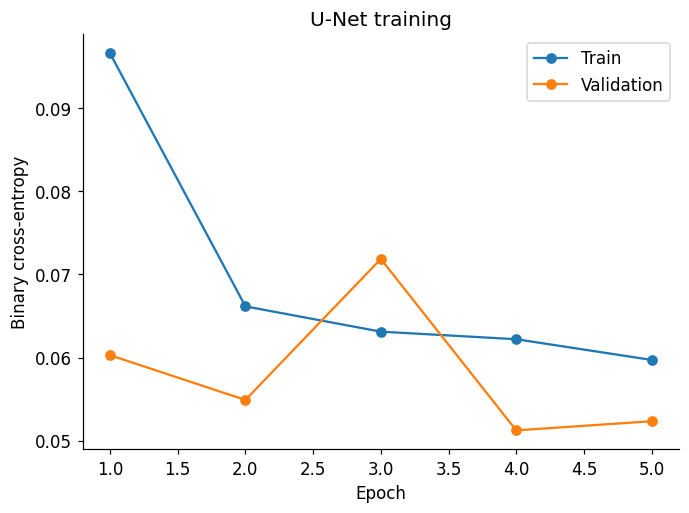

In [27]:
def run_epoch(loader, training):
    model.train(training)
    loss_sum = 0.0; pixels = 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        with torch.set_grad_enabled(training):
            logits = model(x)
            loss = criterion(logits, y)
            if training:
                optimizer.zero_grad(set_to_none=True)
                loss.backward()
                optimizer.step()
        loss_sum += loss.item() * y.numel()
        pixels += y.numel()
    return loss_sum / pixels

history = []; best_loss = float("inf"); best_state = None
for epoch in range(1, (1 if SMOKE_ONLY else EPOCHS) + 1):
    train_loss = run_epoch(train_loader, True)
    val_loss = run_epoch(val_loader, False)
    history.append(dict(epoch=epoch, train_loss=train_loss, validation_loss=val_loss))
    print(f"Epoch {epoch}: train BCE={train_loss:.5f}, validation BCE={val_loss:.5f}")
    if val_loss < best_loss:
        best_loss = val_loss
        best_state = {key: value.detach().cpu().clone() for key, value in model.state_dict().items()}
model.load_state_dict(best_state)
model.eval()
pd.DataFrame(history).to_csv(UNET_OUT / "training_history.csv", index=False)
fig, ax = plt.subplots()
h = pd.DataFrame(history)
ax.plot(h.epoch, h.train_loss, "o-", label="Train")
ax.plot(h.epoch, h.validation_loss, "o-", label="Validation")
ax.set(xlabel="Epoch", ylabel="Binary cross-entropy", title="U-Net training")
ax.legend(); fig.tight_layout(); fig.savefig(UNET_OUT / "training_loss.png"); plt.show()

@torch.inference_mode()
def predict_probability(raw_power):
    model.eval()
    x = torch.from_numpy((raw_power.astype(np.float32) - NORM_MEAN) / NORM_STD)
    return model(x[None, None].to(device)).sigmoid()[0, 0].cpu().numpy()

# Save weights before lengthy evaluation, too.
torch.save(dict(state_dict=best_state, mean=NORM_MEAN, std=NORM_STD,
                base_channels=BASE_CHANNELS, smoke_only=SMOKE_ONLY, seed=SEED), UNET_OUT / "model.pt")

### Validation calibration without storing billions of probabilities
We stream probabilities into 2,048 bins. PR curves and **binned approximate average precision** use these histograms, avoiding multi-GB arrays. This approximation merges scores inside each bin; increase `N_BINS` to check sensitivity. Baseline masks supply individual points, not curves.

We choose a separate U-Net threshold for each baseline's **clean-validation** false-positive rate. Binning/ties can prevent exact matching; the achieved U-Net rate is printed. Calibration always uses validation, even when final evaluation uses test. The default operating point matches `sk-bandpass`.

In [28]:
N_BINS = 2048
EDGES = np.linspace(0, 1, N_BINS + 1)

def histogram_counts(probability, truth):
    return (np.histogram(probability[truth], bins=EDGES)[0],
            np.histogram(probability[~truth], bins=EDGES)[0])

def threshold_for_rate(negative_hist, target_rate):
    # Candidate t=i/N_BINS predicts p>t; no score arrays are kept in memory.
    tails = np.r_[np.cumsum(negative_hist[::-1])[::-1], 0]
    rates = tails / negative_hist.sum()
    index = np.flatnonzero(rates <= target_rate)[0]
    return float(EDGES[index]), float(rates[index])

clean_val = catalog.query("split == 'validation' and rfi_type == 'clean'")
clean_negative_hist = np.zeros(N_BINS, dtype=np.int64)
clean_baseline = {method: [0, 0] for method in METHODS}
for row in clean_val.itertuples():
    for antenna in range(10):
        s = load_sample(DATA, int(row.sample_id), antenna=antenna)
        prob = predict_probability(s["power"])
        clean_negative_hist += np.histogram(prob, bins=EDGES)[0]
        for method in METHODS:
            flags = flag_rfi(s["power"], method=method)
            clean_baseline[method][0] += int(flags.sum())
            clean_baseline[method][1] += flags.size
thresholds = {}; calibration = []
for method, (flagged, total_pixels) in clean_baseline.items():
    target = flagged / total_pixels
    threshold, achieved = threshold_for_rate(clean_negative_hist, target)
    thresholds[method] = threshold
    calibration.append(dict(matched_to=method, baseline_clean_fpr=target,
                            threshold=threshold, unet_binned_clean_fpr=achieved))
calibration = pd.DataFrame(calibration)
display(calibration)
calibration.to_csv(UNET_OUT / "threshold_calibration.csv", index=False)
THRESHOLD = thresholds["sk-bandpass"]
torch.save(dict(state_dict=best_state, mean=NORM_MEAN, std=NORM_STD,
                base_channels=BASE_CHANNELS, thresholds=thresholds,
                smoke_only=SMOKE_ONLY, seed=SEED), UNET_OUT / "model.pt")
print("Default frozen probability threshold:", THRESHOLD)

,matched_to,baseline_clean_fpr,threshold,unet_binned_clean_fpr
0,sk,0.007031,0.048340,0.006912
1,bandpass,0.000000,0.516113,0.000000
2,sk-bandpass,0.012240,0.039551,0.011869


Default frozen probability threshold: 0.03955078125


### Evaluate masks and build the PR curve
This pass scores all antennas in the selected split. It includes the three unchanged reference baselines and each matched U-Net operating point. Success/failure examples below are selected within this split for illustration, not for further tuning on test.

For sky controls, `power_retained` is the fraction of **total measured power** left after masking, including receiver noise. It is a useful control diagnostic, not a direct estimate of astronomical pulse flux retention.

Scored 10/60 validation recordings
Scored 20/60 validation recordings
Scored 30/60 validation recordings
Scored 40/60 validation recordings
Scored 50/60 validation recordings
Scored 60/60 validation recordings


precision    recall  false_positive_rate  \
rfi_type method                                                             
ask      bandpass                 0.279358  0.242608             0.004537   
         sk                       0.048114  0.067901             0.009738   
         sk-bandpass              0.103156  0.903326             0.056930   
         unet_match_bandpass      0.881733  0.180202             0.000175   
         unet_match_sk            0.288136  0.600813             0.010760   
...                                    ...       ...                  ...   
wireless sk                       0.045937  0.117027             0.023835   
         sk-bandpass              0.045147  0.289349             0.060012   
         unet_match_bandpass      0.890494  0.373209             0.000450   
         unet_match_sk            0.401869  0.657372             0.009595   
         unet_match_sk-bandpass   0.308571  0.680496             0.014953   

                                  removed  
rfi_type method                            
ask      bandpass                0.006250  
         sk                      0.010156  
         sk-bandpass             0.063021  
         unet_match_bandpass     0.001471  
         unet_match_sk           0.015006  
...                                   ...  
wireless sk                      0.024740  
         sk-bandpass             0.062240  
         unet_match_bandpass     0.004070  
         unet_match_sk           0.015885  
         unet_match_sk-bandpass  0.021416  

[78 rows x 4 columns]

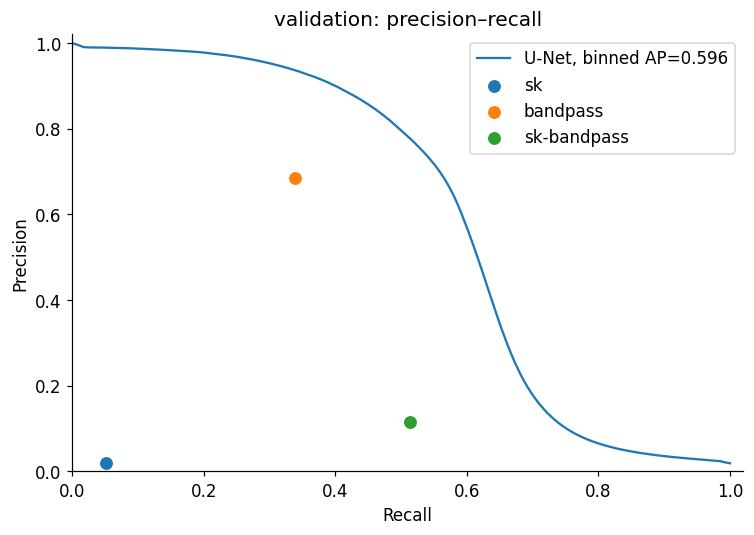

Binned approximate average precision: 0.5957716884382254


In [29]:
assert EVAL_SPLIT in ("validation", "test")
eval_frame = catalog.loc[catalog.split.eq(EVAL_SPLIT)]
if SMOKE_ONLY: eval_frame = eval_frame.head(1)
positive_hist = np.zeros(N_BINS, dtype=np.int64)
negative_hist = np.zeros(N_BINS, dtype=np.int64)
evaluation_rows = []
for number, row in enumerate(eval_frame.itertuples(), 1):
    for antenna in range(10):
        s = load_sample(DATA, int(row.sample_id), antenna=antenna)
        raw, truth = s["power"], s["rfi_mask"]
        prob = predict_probability(raw)
        ph, nh = histogram_counts(prob, truth)
        positive_hist += ph; negative_hist += nh
        predictions = {method: flag_rfi(raw, method=method) for method in METHODS}
        predictions.update({f"unet_match_{method}": prob > threshold
                            for method, threshold in thresholds.items()})
        for method, flags in predictions.items():
            metrics = score_mask(flags, truth)
            evaluation_rows.append(dict(sample_id=int(row.sample_id), antenna=antenna,
                rfi_type=row.rfi_type, method=method,
                power_sum=float(raw.sum(dtype=np.float64)),
                retained_power_sum=float(raw[~flags].sum(dtype=np.float64)), **metrics))
    if number % 10 == 0: print(f"Scored {number}/{len(eval_frame)} {EVAL_SPLIT} recordings")
results = pd.DataFrame(evaluation_rows)
results.to_csv(UNET_OUT / f"{EVAL_SPLIT}_per_antenna.csv", index=False)

def pooled_table(frame, groups):
    table = frame.groupby(groups)[["tp", "fp", "fn", "tn", "power_sum", "retained_power_sum"]].sum()
    table["precision"] = table.tp / (table.tp + table.fp).replace(0, np.nan)
    table["recall"] = table.tp / (table.tp + table.fn).replace(0, np.nan)
    table["false_positive_rate"] = table.fp / (table.fp + table.tn).replace(0, np.nan)
    table["removed"] = (table.tp + table.fp) / (table.tp + table.fp + table.fn + table.tn)
    table["power_retained"] = table.retained_power_sum / table.power_sum
    return table

family_table = pooled_table(results, ["rfi_type", "method"])
family_table.to_csv(UNET_OUT / f"{EVAL_SPLIT}_by_family.csv")
overall_table = pooled_table(results, "method")
display(family_table[["precision", "recall", "false_positive_rate", "removed"]])
# PR points correspond to thresholds from high to low probability.
tp_curve = np.cumsum(positive_hist[::-1])
fp_curve = np.cumsum(negative_hist[::-1])
pr_precision = np.divide(tp_curve, tp_curve + fp_curve,
                         out=np.ones_like(tp_curve, dtype=float), where=(tp_curve + fp_curve)>0)
pr_recall = tp_curve / positive_hist.sum() if positive_hist.sum() else np.full(N_BINS, np.nan)
ap = float(np.sum(np.diff(np.r_[0, pr_recall]) * pr_precision))
fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(np.r_[0, pr_recall], np.r_[1, pr_precision], label=f"U-Net, binned AP={ap:.3f}")
for method in METHODS:
    score = overall_table.loc[method]
    ax.scatter(score.recall, score.precision, label=method, s=55)
ax.set(xlabel="Recall", ylabel="Precision", xlim=(0, 1.02), ylim=(0, 1.02), title=f"{EVAL_SPLIT}: precision–recall")
ax.legend(); fig.tight_layout(); fig.savefig(UNET_OUT / f"{EVAL_SPLIT}_precision_recall.png"); plt.show()
np.savez(UNET_OUT / f"{EVAL_SPLIT}_pr_histograms.npz", positive=positive_hist, negative=negative_hist, edges=EDGES)
print("Binned approximate average precision:", ap)

### Example predictions and control plots
Rank positive examples by intersection-over-union (IoU) at the frozen threshold. Inspect the best and worst, remembering that even the best case may be poor after a short training run. Display averaging changes only the visualization, never the scores.

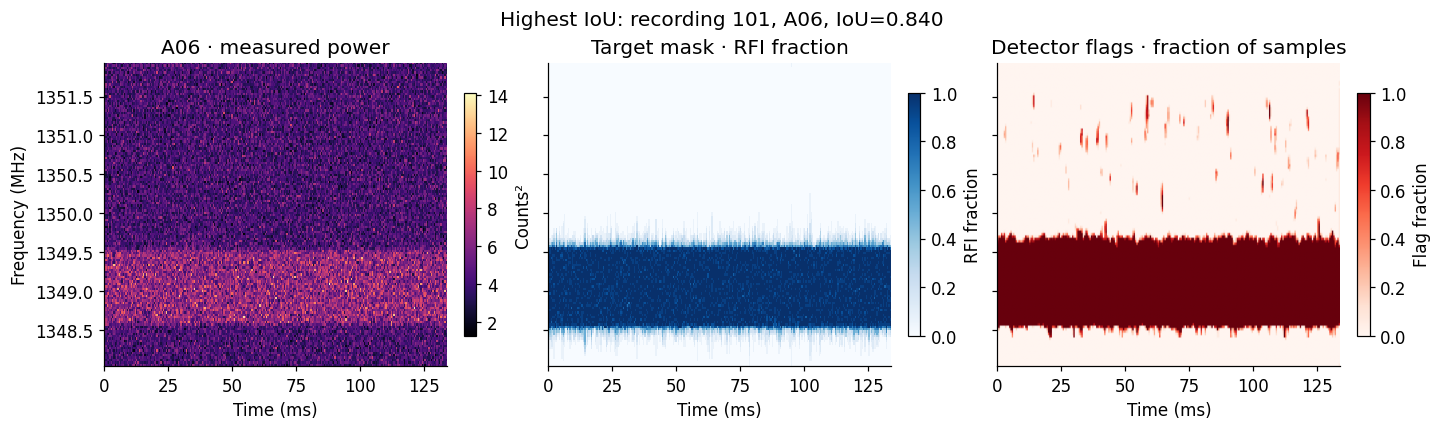

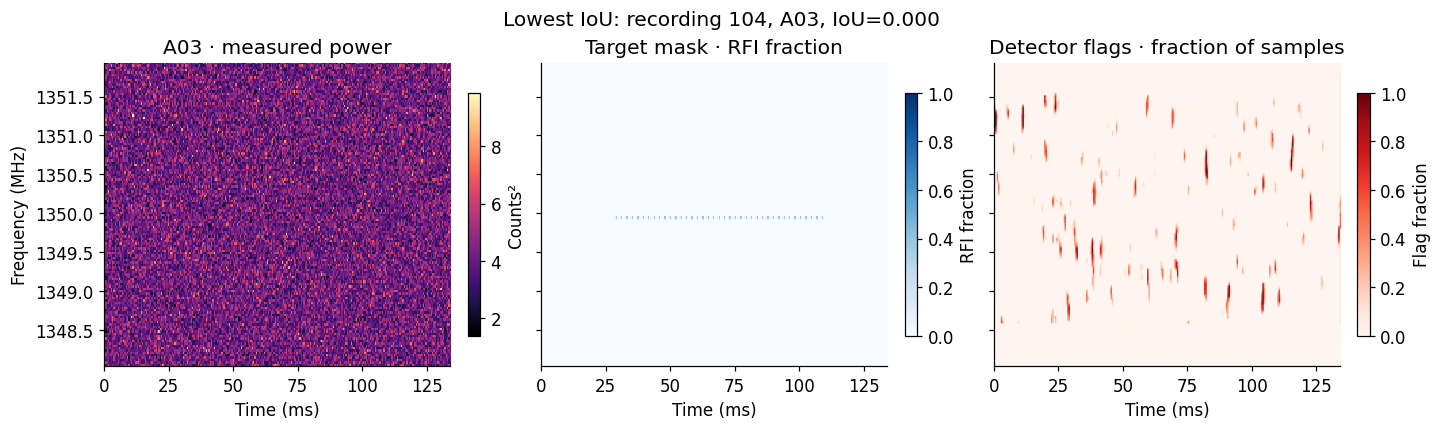

false_positive_rate   removed  power_retained
rfi_type method                                                               
clean    bandpass                           0.000000  0.000000        1.000000
         sk                                 0.007031  0.007031        0.992950
         sk-bandpass                        0.012240  0.012240        0.987735
         unet_match_bandpass                0.000000  0.000000        1.000000
         unet_match_sk                      0.006912  0.006912        0.990805
         unet_match_sk-bandpass             0.011869  0.011869        0.984409
sky      bandpass                           0.000260  0.000260        0.999724
         sk                                 0.009896  0.009896        0.990079
         sk-bandpass                        0.013802  0.013802        0.986141
         unet_match_bandpass                0.006588  0.006588        0.989837
         unet_match_sk                      0.036725  0.036725        0.953259
         unet_match_sk-bandpass             0.043652  0.043652        0.944696

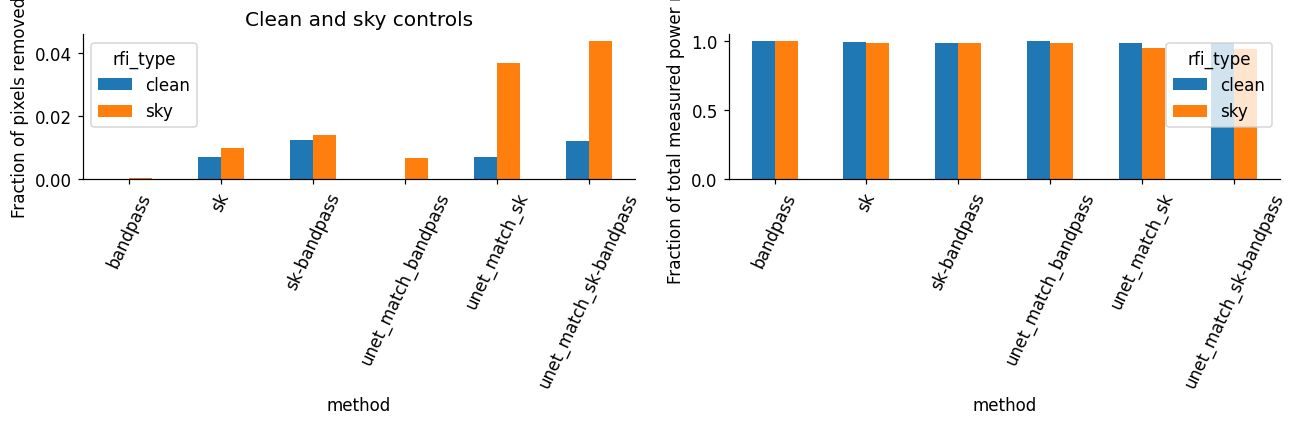

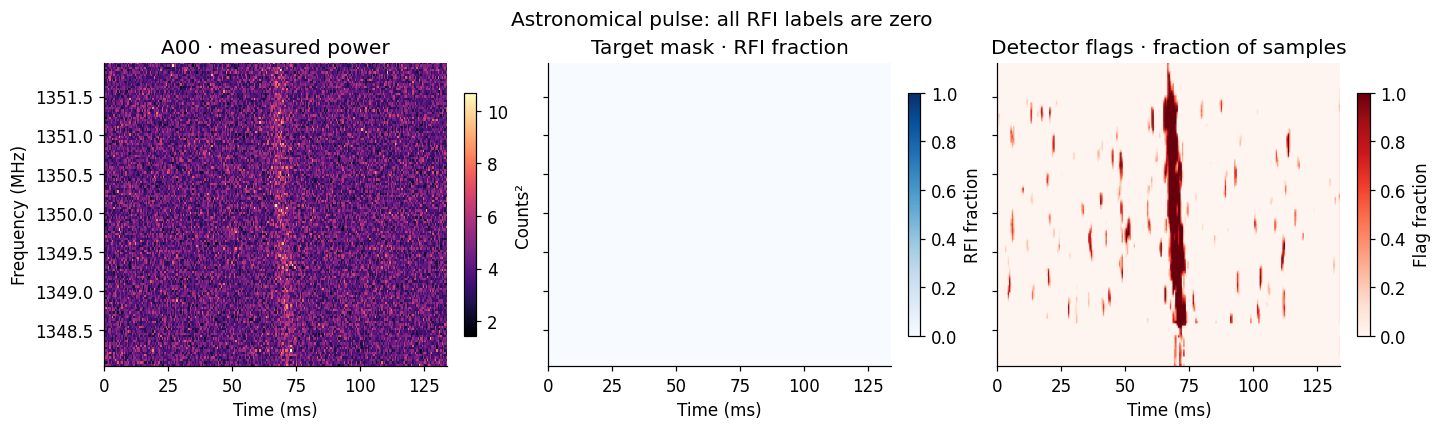

In [30]:
operating_name = "unet_match_sk-bandpass"
examples = results.loc[(results.method == operating_name) & ((results.tp + results.fn) > 0)].copy()
examples["iou"] = examples.tp / (examples.tp + examples.fp + examples.fn)
if len(examples):
    for title, row in [("Highest IoU", examples.loc[examples.iou.idxmax()]),
                       ("Lowest IoU", examples.loc[examples.iou.idxmin()])]:
        s = load_sample(DATA, int(row.sample_id), antenna=int(row.antenna))
        flags = predict_probability(s["power"]) > THRESHOLD
        fig = plot_sample(s, flags, factor=16)
        fig.suptitle(f"{title}: recording {int(row.sample_id)}, A{int(row.antenna):02d}, IoU={row.iou:.3f}")
        fig.savefig(UNET_OUT / f"{EVAL_SPLIT}_{title.replace(' ', '_')}.png", bbox_inches="tight")
        plt.show()
control = family_table.loc[family_table.index.get_level_values("rfi_type").isin(["clean", "sky"])]
if len(control):
    display(control[["false_positive_rate", "removed", "power_retained"]])
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    control["removed"].unstack("rfi_type").plot.bar(ax=axes[0], rot=65)
    control["power_retained"].unstack("rfi_type").plot.bar(ax=axes[1], rot=65)
    axes[0].set(ylabel="Fraction of pixels removed", title="Clean and sky controls")
    axes[1].set(ylabel="Fraction of total measured power retained", ylim=(0, 1.05))
    fig.tight_layout(); fig.savefig(UNET_OUT / f"{EVAL_SPLIT}_controls.png"); plt.show()
for row in eval_frame.loc[eval_frame.rfi_type.eq("sky")].head(1).itertuples():
    s = load_sample(DATA, int(row.sample_id), antenna=0)
    fig = plot_sample(s, predict_probability(s["power"]) > THRESHOLD, factor=16)
    fig.suptitle("Astronomical pulse: all RFI labels are zero")
    fig.savefig(UNET_OUT / f"{EVAL_SPLIT}_sky_mask.png", bbox_inches="tight"); plt.show()

### Controlled strength and modulation/duty plots
These synthetic diagnostic sweeps keep seed, period, and symbol rate fixed. They use antenna A00 and the frozen network threshold. Strength plots report both source reference strength and received peak injected power as percentages of noise power. Duty curves are separated by modulation. A single seed illustrates behavior; use more independent seeds for a report with uncertainty.

These are separate generated experiments, not the supplied test split. Do not change model settings based on final-test results.

Seed 42 is used because A00 receives nonzero transmitter power for every selected family; other seeds can leave this antenna unaffected.

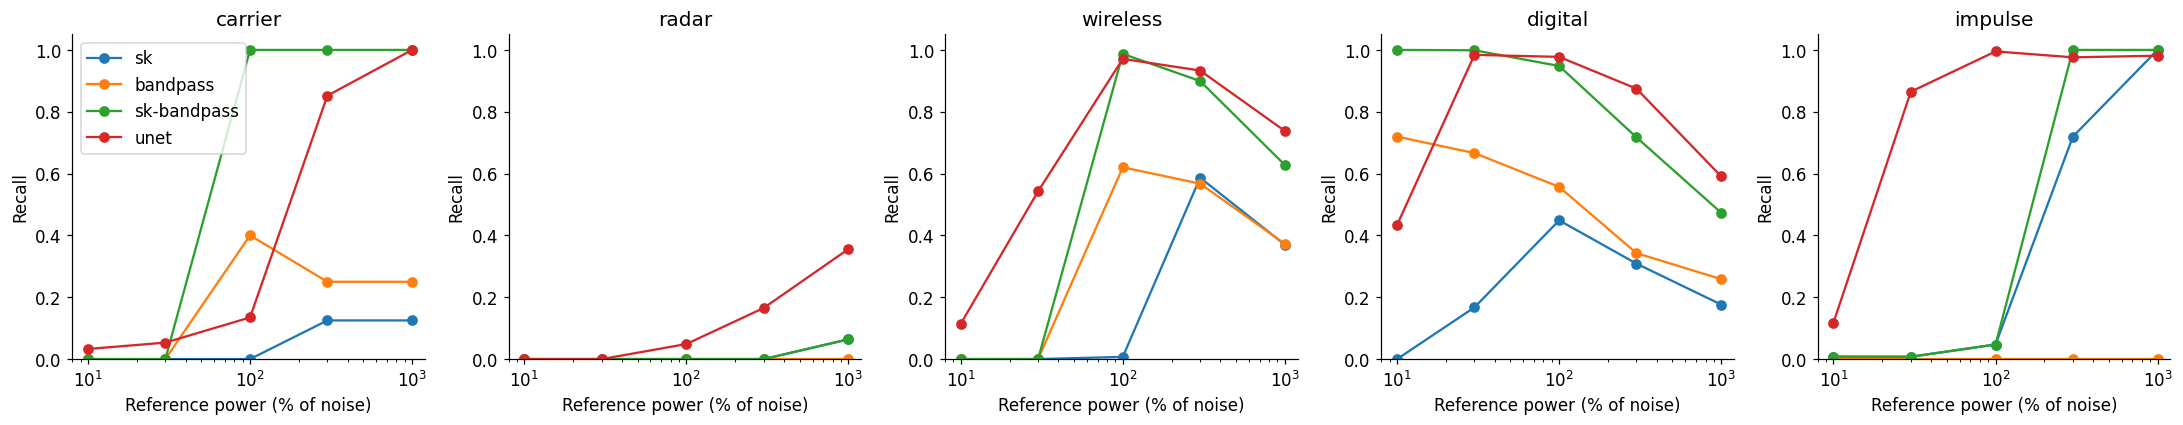

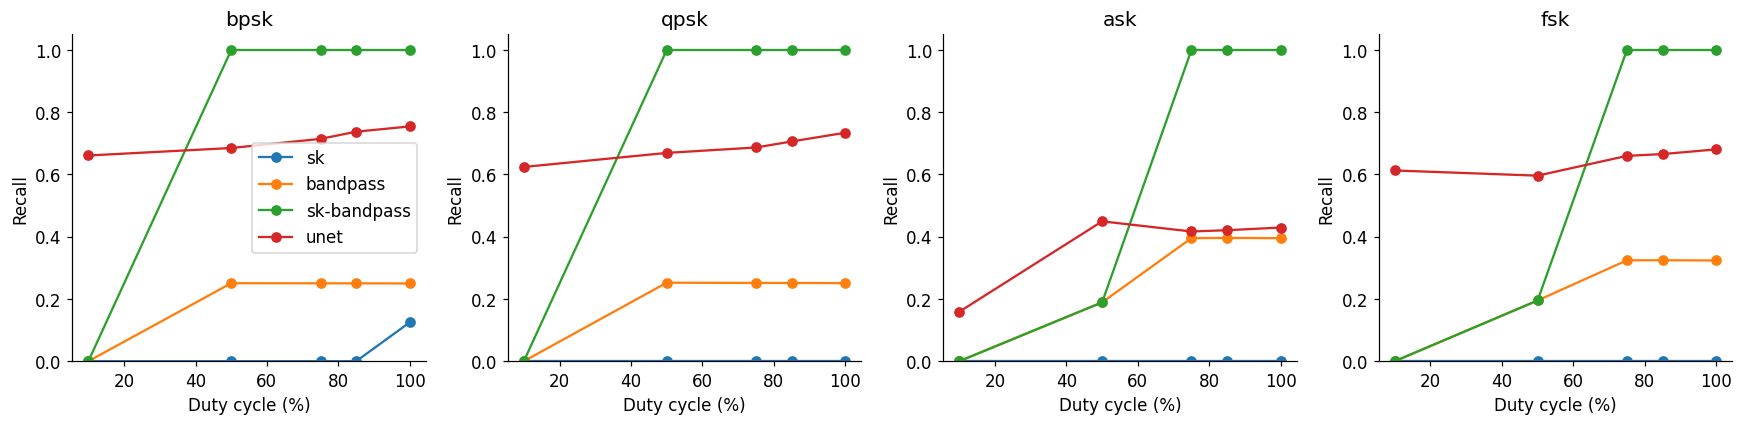

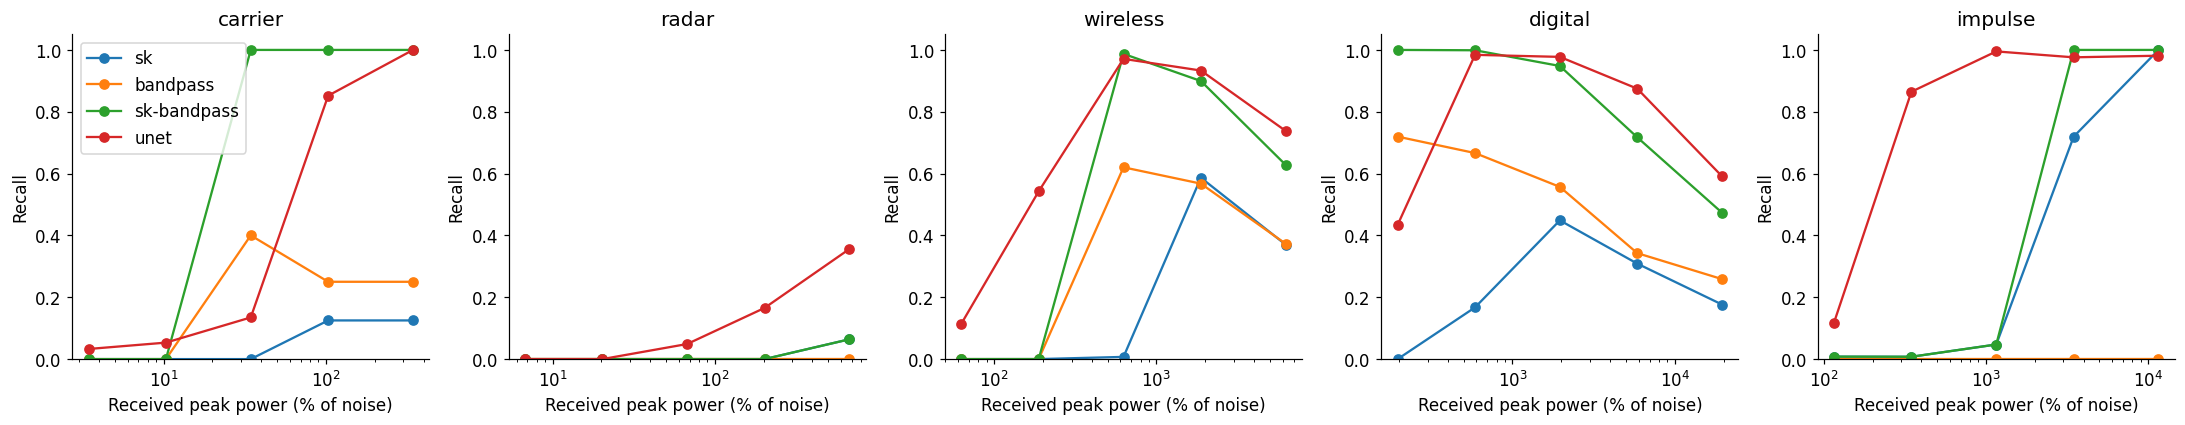

In [31]:
sweep_rows = []

def score_generated(generated, **settings):
    raw = generated["power"][:, 0, :, 0]
    truth = generated["rfi_mask"][:, 0, :, 0]
    noise_power = 2 * generated["metadata"]["sigma"]**2
    peak_percent = 100 * float(generated["injected_power"][:, 0, :, 0].max()) / noise_power
    predictions = {method: flag_rfi(raw, method=method) for method in METHODS}
    predictions["unet"] = predict_probability(raw) > THRESHOLD
    for method, flags in predictions.items():
        sweep_rows.append(dict(**settings, seed=42, method=method, received_peak_percent=peak_percent,
                               **score_mask(flags, truth)))

for family in ("carrier", "radar", "wireless", "digital", "impulse"):
    for strength in (0.1, 0.3, 1.0, 3.0, 10.0):
        generated = simulate_recording(seed=42, rfi=family, strength=strength)
        score_generated(generated, experiment="strength", family=family,
                        reference_percent=100*strength, duty_cycle=np.nan)
for modulation in ("bpsk", "qpsk", "ask", "fsk"):
    for duty in (0.10, 0.50, 0.75, 0.85, 1.0):
        generated = simulate_recording(seed=42, rfi=modulation, strength=1.0,
                                       duty_cycle=duty, period_s=0.01, symbol_rate=3000)
        score_generated(generated, experiment="duty", family=modulation,
                        reference_percent=100.0, duty_cycle=duty)
sweeps = pd.DataFrame(sweep_rows)
sweeps.to_csv(UNET_OUT / "controlled_sweeps.csv", index=False)

for experiment in ("strength", "duty"):
    subset = sweeps.loc[sweeps.experiment.eq(experiment)]
    families = subset.family.unique()
    fig, axes = plt.subplots(1, len(families), figsize=(4*len(families), 4), squeeze=False)
    for ax, family in zip(axes[0], families):
        for method in (*METHODS, "unet"):
            curve = subset.loc[(subset.family == family) & (subset.method == method)]
            x = curve.reference_percent if experiment == "strength" else 100*curve.duty_cycle
            ax.plot(x, curve.recall, "o-", label=method)
        ax.set(title=family, ylabel="Recall", ylim=(0, 1.05),
               xlabel="Reference power (% of noise)" if experiment == "strength" else "Duty cycle (%)")
        if experiment == "strength":
            ax.set_xscale("log")
            ax.set_xlim(8, 1200)
    axes[0, 0].legend(); fig.tight_layout()
    fig.savefig(UNET_OUT / f"{experiment}_recall.png"); plt.show()
# Also plot received peak, separately from source reference strength.
strength_data = sweeps.loc[sweeps.experiment.eq("strength")]
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for ax, family in zip(axes, strength_data.family.unique()):
    for method in (*METHODS, "unet"):
        curve = strength_data.loc[(strength_data.family == family) & (strength_data.method == method)].sort_values("received_peak_percent")
        ax.plot(curve.received_peak_percent, curve.recall, "o-", label=method)
    ax.set(title=family, xlabel="Received peak power (% of noise)", ylabel="Recall", ylim=(0, 1.05), xscale="log")
axes[0].legend(); fig.tight_layout(); fig.savefig(UNET_OUT / "received_peak_recall.png"); plt.show()

### Interpreting and saving your result
A short run may predict mostly clean pixels because positives are rare. Inspect loss, PR/AP, and masks together. Increase epochs or investigate training-only class weighting only after validating the basic pipeline. Choose those changes using validation, then freeze them before test.

`outputs/unet/model.pt` stores the best-validation-loss weights, normalization, architecture width, and calibrated thresholds. To reload it, instantiate `SmallUNet(checkpoint["base_channels"])`, load `checkpoint["state_dict"]`, and restore its normalization and thresholds. Record the seed, epoch budget, split, and `SMOKE_ONLY` setting in your report. The smoke run and a five-epoch run do not establish convergence.

### Pulse-specific astronomical retention and clean-data removal
Run after the U-Net prediction and threshold cells. This completes the control comparison using the CSV-selected `clean` and `sky` recordings in `EVAL_SPLIT`. Test remains reserved until settings are frozen.

For clean controls, report the fraction of native pixels flagged. For sky controls, reconstruct the **actual injected astronomical voltage component** using the saved simulator seed and measure

`pulse energy retained = sum(|sky_voltage|² × unflagged) / sum(|sky_voltage|²)`.

Unlike total measured power, this denominator excludes receiver noise. It measures how much of the known simulated pulse lies in retained pixels **before quantization**; it is not a calibrated flux or signal-to-noise measurement after quantization. The original stored input is passed to every detector. Reconstruction is used only to score the predictions; sky RFI labels remain all zero. A full regenerated-power equality check guards against using a different simulator/data version.

The second plot aligns frequency channels by the known dispersion arrival time. It shows the retained injected pulse profile, without renormalizing away lost energy. These seeded synthetic controls do not establish preservation of all possible astronomical signals.

In [ ]:
from cs163_rfi.voltage import noise as receiver_noise
from cs163_rfi.simulation import make_scene, CUBE_SAMPLES

CONTROL_METHODS = (*METHODS, *(f"unet_match_{method}" for method in METHODS))

def reconstruct_sky_component(recording):
    metadata = recording["metadata"]
    settings = metadata["generator"]
    assert settings["rfi"] == "sky"
    assert not recording["rfi_mask"].any(), "Sky must have no RFI labels"
    nt = len(recording["power"])
    assert nt % CUBE_SAMPLES == 0
    seed = int(settings["seed"])
    scene = make_scene(seed, "sky", settings["strength"], cubes=nt // CUBE_SAMPLES)
    regenerated = simulate_recording(**settings)
    np.testing.assert_array_equal(recording["power"], regenerated["power"])
    dt = metadata["dt_s"]
    times = np.arange(nt) * dt
    frequencies = recording["frequency_mhz"]
    arrival = nt * dt / 2 + 4.148808e3 * 400 * (frequencies**-2 - frequencies.max()**-2)
    envelope = np.exp(-0.5 * ((times[:, None] - arrival) / 0.002)**2)
    pieces = []
    for cube in range(nt // CUBE_SAMPLES):
        sky = receiver_noise((CUBE_SAMPLES, 1, len(frequencies), 1),
                             np.random.default_rng([seed, cube, 772]), scene["sigma"])
        env = envelope[cube*CUBE_SAMPLES:(cube+1)*CUBE_SAMPLES]
        component = sky * np.sqrt(0.3 * env[:, None, :, None])
        pieces.append(np.abs(component[:, 0, :, 0]).astype(np.float64)**2)
    return np.concatenate(pieces), 1000 * (times[:, None] - arrival)


def control_predictions(raw):
    predictions = {method: flag_rfi(raw, method=method)
                   for method in METHODS if method in CONTROL_METHODS}
    if any(method.startswith("unet_match_") for method in CONTROL_METHODS):
        probability = predict_probability(raw)
        for method in METHODS:
            name = f"unet_match_{method}"
            if name in CONTROL_METHODS:
                predictions[name] = probability > thresholds[method]
    return predictions

control_frame = catalog.loc[catalog.split.eq(EVAL_SPLIT) & catalog.rfi_type.isin(["clean", "sky"])]
assert set(control_frame.rfi_type) == {"clean", "sky"}
control_rows = []
profile_edges_ms = np.linspace(-8, 8, 65)
profile_original = np.zeros(len(profile_edges_ms) - 1)
profile_retained = {method: np.zeros_like(profile_original) for method in CONTROL_METHODS}
for row in control_frame.itertuples():
    recording = load_recording(DATA / row.path)
    assert not recording["rfi_mask"].any()
    if row.rfi_type == "sky":
        sky_energy, relative_time_ms = reconstruct_sky_component(recording)
    for antenna in range(recording["power"].shape[1]):
        raw = recording["power"][:, antenna, :, 0]
        if row.rfi_type == "sky":
            original = np.histogram(relative_time_ms, bins=profile_edges_ms, weights=sky_energy)[0]
            profile_original += original
        for method, flags in control_predictions(raw).items():
            retained = ~flags
            control_rows.append(dict(sample_id=int(row.sample_id), antenna=antenna,
                rfi_type=row.rfi_type, method=method,
                flagged_pixels=int(flags.sum()), total_pixels=flags.size,
                pulse_energy=(float(sky_energy.sum()) if row.rfi_type == "sky" else 0.0),
                retained_pulse_energy=(float(sky_energy[retained].sum()) if row.rfi_type == "sky" else 0.0)))
            if row.rfi_type == "sky":
                profile_retained[method] += np.histogram(relative_time_ms, bins=profile_edges_ms,
                                                         weights=sky_energy * retained)[0]
    print(f"Scored {row.rfi_type} control {row.sample_id}")
control_detail = pd.DataFrame(control_rows)
control_detail.to_csv(UNET_OUT / f"{EVAL_SPLIT}_pulse_retention_per_antenna.csv", index=False)
control_sums = control_detail.groupby(["rfi_type", "method"])[
    ["flagged_pixels", "total_pixels", "pulse_energy", "retained_pulse_energy"]].sum()
control_summary = pd.DataFrame(index=pd.Index(CONTROL_METHODS, name="method"))
control_summary["clean_removed"] = (control_sums.loc["clean", "flagged_pixels"] /
                                     control_sums.loc["clean", "total_pixels"])
control_summary["sky_pixels_removed"] = (control_sums.loc["sky", "flagged_pixels"] /
                                          control_sums.loc["sky", "total_pixels"])
control_summary["astronomical_pulse_energy_retained"] = (
    control_sums.loc["sky", "retained_pulse_energy"] / control_sums.loc["sky", "pulse_energy"])
control_summary.to_csv(UNET_OUT / f"{EVAL_SPLIT}_pulse_retention_summary.csv")
display(control_summary.style.format("{:.2%}"))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
(100 * control_summary.clean_removed).plot.bar(ax=axes[0], rot=60)
(100 * control_summary.astronomical_pulse_energy_retained).plot.bar(ax=axes[1], rot=60)
axes[0].set(ylabel="Noise-only pixels removed (%)", title=f"{EVAL_SPLIT}: clean removal")
axes[1].set(ylabel="Injected pulse energy retained (%)", ylim=(0, 105),
            title=f"{EVAL_SPLIT}: astronomical retention")
fig.tight_layout()
fig.savefig(UNET_OUT / f"{EVAL_SPLIT}_clean_and_pulse_retention.png", bbox_inches="tight")
plt.show()

centers_ms = 0.5 * (profile_edges_ms[:-1] + profile_edges_ms[1:])
normalizer = profile_original.max()
assert normalizer > 0
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(centers_ms, profile_original / normalizer, "k--", linewidth=2, label="Original injected pulse")
for method, profile in profile_retained.items():
    ax.plot(centers_ms, profile / normalizer, label=method)
ax.set(xlabel="Time relative to dispersed arrival (ms)",
       ylabel="Injected energy per bin / original peak bin energy",
       title="Astronomical pulse after masking (channels aligned in time)")
ax.legend(fontsize=8); fig.tight_layout()
fig.savefig(UNET_OUT / f"{EVAL_SPLIT}_retained_pulse_profile.png", bbox_inches="tight")
plt.show()
np.savez(UNET_OUT / f"{EVAL_SPLIT}_retained_pulse_profile.npz", time_ms=centers_ms,
         original=profile_original, **profile_retained)


### Report summary: RFI detection versus astronomical preservation
Run after the evaluation and pulse-retention cells. This grouped chart compares the unchanged combined baseline with the U-Net threshold matched to its clean-validation false-positive rate. RFI recall pools positive pixels across the evaluated recordings; astronomical retention measures injected pulse energy before quantization, excluding receiver noise. Both use the selected evaluation split.

The legend states the number of epochs run. The model itself is the checkpoint with the lowest validation loss within that run. Values come from the result tables, not the example chart.

In [ ]:
from matplotlib.ticker import PercentFormatter

comparison_methods = ["sk-bandpass", "unet_match_sk-bandpass"]
# Recalculate pooled recall from native confusion counts, not a mean of family recalls.
summary_counts = results.groupby("method")[["tp", "fn"]].sum()
recall_values = summary_counts.tp / (summary_counts.tp + summary_counts.fn).replace(0, np.nan)
summary_plot_data = pd.DataFrame({
    "RFI recall": recall_values.reindex(comparison_methods),
    "Sky pulse energy retained": control_summary.loc[
        comparison_methods, "astronomical_pulse_energy_retained"],
})
assert np.isfinite(summary_plot_data.to_numpy()).all(), "Run full evaluation and pulse retention first"
assert summary_plot_data.ge(0).all().all() and summary_plot_data.le(1).all().all()
epochs_run = len(history)
labels = ["Combined baseline", f"U-Net ({epochs_run} epoch{'s' if epochs_run != 1 else ''})"]
if SMOKE_ONLY: labels[1] += " — smoke run"
colors = ["#00867F", "#E36B4B"]
positions = np.arange(len(summary_plot_data.columns))
bar_width = 0.34
fig, ax = plt.subplots(figsize=(10, 5.2))
for index, (method, label, color) in enumerate(zip(comparison_methods, labels, colors)):
    bars = ax.bar(positions + (index - 0.5)*bar_width,
                  summary_plot_data.loc[method].to_numpy(), width=bar_width,
                  color=color, label=label)
    ax.bar_label(bars, labels=[f"{100*bar.get_height():.1f}%" for bar in bars],
                 padding=5, fontsize=12)
ax.set_xticks(positions, summary_plot_data.columns)
ax.set_ylim(0, 1.13)
ax.set_yticks(np.linspace(0, 1, 6))
ax.yaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
ax.grid(axis="y", color="#E8ECEC", linewidth=0.8)
ax.set_axisbelow(True)
for spine in ax.spines.values(): spine.set_visible(False)
ax.tick_params(axis="both", length=0, labelsize=12)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, 1.12), ncol=2,
          frameon=False, fontsize=12)
ax.set_title(f"{EVAL_SPLIT.capitalize()}: RFI detection and astronomical preservation", pad=46)
fig.tight_layout()
fig.savefig(UNET_OUT / f"{EVAL_SPLIT}_recall_and_pulse_retention.png", dpi=200, bbox_inches="tight")
fig.savefig(UNET_OUT / f"{EVAL_SPLIT}_recall_and_pulse_retention.pdf", bbox_inches="tight")
summary_plot_data.to_csv(UNET_OUT / f"{EVAL_SPLIT}_recall_and_pulse_retention.csv")
plt.show()
display(summary_plot_data.style.format("{:.1%}"))
